In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

In [2]:
CSV_PATH = "csv/dataset_final.csv"  # <-- ajusta a tu ruta real
df = pd.read_csv(CSV_PATH)
 
print(f"Dataset cargado: {df.shape[0]} filas, {df.shape[1]} columnas")

Dataset cargado: 29991 filas, 59 columnas


In [3]:
cols_comp = [c for c in df.columns if c.startswith("comp_")]
print(f"\nColumnas comp_ a eliminar ({len(cols_comp)}):")
print(cols_comp)
 
df = df.drop(columns=cols_comp)
 
print(f"\nDataset resultante: {df.shape[0]} filas, {df.shape[1]} columnas")
print("\nColumnas restantes:")
print(df.columns.tolist())

df.to_csv("csv/dataset_final_orig.csv", index=False)

df.info()
 


Columnas comp_ a eliminar (26):
['comp_media_lum', 'comp_var_lum', 'comp_rango', 'comp_std', 'comp_michelson', 'comp_hf', 'comp_lf', 'comp_hlfr', 'comp_edges_s1', 'comp_edges_s2', 'comp_edges_s3', 'comp_grad_mean', 'comp_grad_std', 'comp_glcm_contrast', 'comp_glcm_hom', 'comp_glcm_energy', 'comp_glcm_corr', 'comp_entropia_shannon', 'comp_entropia_espectral', 'comp_entropia_gradiente', 'comp_entropia_glcm', 'comp_sat_mean', 'comp_sat_var', 'comp_hue_var', 'comp_megapixeles', 'comp_aspect_ratio']

Dataset resultante: 29991 filas, 33 columnas

Columnas restantes:
['img_original', 'img_recodificada', 'metodo', 'formato_salida', 'calidad', 'orig_media_lum', 'orig_var_lum', 'orig_rango', 'orig_std', 'orig_michelson', 'orig_hf', 'orig_lf', 'orig_hlfr', 'orig_edges_s1', 'orig_edges_s2', 'orig_edges_s3', 'orig_grad_mean', 'orig_grad_std', 'orig_glcm_contrast', 'orig_glcm_hom', 'orig_glcm_energy', 'orig_glcm_corr', 'orig_entropia_shannon', 'orig_entropia_espectral', 'orig_entropia_gradiente', '

In [3]:
df = pd.read_csv("csv/dataset_final_orig.csv")
print(f"Dataset cargado: {df.shape[0]} filas, {df.shape[1]} columnas")

Dataset cargado: 29991 filas, 33 columnas


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29991 entries, 0 to 29990
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   img_original             29991 non-null  object 
 1   img_recodificada         29991 non-null  object 
 2   metodo                   29991 non-null  object 
 3   formato_salida           29991 non-null  object 
 4   calidad                  29991 non-null  int64  
 5   orig_media_lum           29991 non-null  float64
 6   orig_var_lum             29991 non-null  float64
 7   orig_rango               29991 non-null  float64
 8   orig_std                 29991 non-null  float64
 9   orig_michelson           29991 non-null  float64
 10  orig_hf                  29991 non-null  float64
 11  orig_lf                  29991 non-null  float64
 12  orig_hlfr                29991 non-null  float64
 13  orig_edges_s1            29991 non-null  float64
 14  orig_edges_s2         

# Análisis descriptivo de variables numéricas y variable objetivo

# CELDA 0 — SETUP

In [5]:
OUT_DIR = "csv/eda_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
 
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = ["metodo", "formato_salida", "formato_entrada"]
target = "lpips"

features = [c for c in num_cols if c != target]

features_img = [c for c in features if c != "calidad"]
 
print(f"Dataset: {df.shape[0]} filas, {df.shape[1]} columnas")
print(f"Numericas: {len(num_cols)} | Categoricas: {cat_cols} | Target: {target}")
print(f"Features (numericas sin target): {len(features)} | Features de imagen: {len(features_img)}")

Dataset: 29991 filas, 33 columnas
Numericas: 28 | Categoricas: ['metodo', 'formato_salida', 'formato_entrada'] | Target: lpips
Features (numericas sin target): 27 | Features de imagen: 26


# CELDA 1 — ESTADISTICAS DESCRIPTIVAS

In [6]:
print("=" * 70)
print("1. ESTADISTICAS DESCRIPTIVAS (numericas)")
print("=" * 70)
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurtosis()
print(desc.to_string())
desc.to_csv(f"{OUT_DIR}/estadisticas_descriptivas.csv")
 
print("\n" + "=" * 70)
print("1b. FRECUENCIAS DE VARIABLES CATEGORICAS")
print("=" * 70)
for col in cat_cols + ["calidad"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().to_string())

1. ESTADISTICAS DESCRIPTIVAS (numericas)
                           count           mean            std           min         25%            50%             75%             max       skew     kurtosis
calidad                  29991.0      50.265413      28.257077  1.000000e+01   30.000000      50.000000       70.000000       90.000000  -0.018296    -1.301098
orig_media_lum           29991.0       0.469530       0.158674  0.000000e+00    0.375627       0.453575        0.549925        1.000000   0.382894     0.723681
orig_var_lum             29991.0       0.055864       0.030030  0.000000e+00    0.034811       0.051589        0.072124        0.230775   0.950310     1.578090
orig_rango               29991.0  579508.800851  484866.836302  0.000000e+00  133.315558  991055.686275  1000000.000000  1000000.000000  -0.337258    -1.865887
orig_std                 29991.0       0.227177       0.065232  0.000000e+00    0.186576       0.227131        0.268560        0.480390  -0.090866     0.558323

# CELDA 2 — VALORES NULOS

In [7]:
print("=" * 70)
print("2. VALORES NULOS")
print("=" * 70)
nulos = df.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
print(nulos.to_string() if len(nulos) else "Sin nulos")
 
# Resumen tabular de nulos (conteo + porcentaje), en vez del heatmap
resumen_nulos = pd.DataFrame({
    "n_nulos": nulos,
    "pct_nulos": (nulos / len(df) * 100).round(3)
})
print("\nResumen de nulos:")
print(resumen_nulos.to_string())
resumen_nulos.to_csv(f"{OUT_DIR}/resumen_nulos.csv")
print(f"\nGuardado: {OUT_DIR}/resumen_nulos.csv")
 
for col in nulos.index:
    print(f"\nNulos de '{col}' por metodo:")
    mask = df[col].isna()
    print(df.loc[mask, "metodo"].value_counts().to_string())
    print(f"Nulos de '{col}' por formato_salida:")
    print(df.loc[mask, "formato_salida"].value_counts().to_string())
    print(f"Nulos de '{col}' por formato_entrada:")
    print(df.loc[mask, "formato_entrada"].value_counts().to_string())
    print(f"Nulos de '{col}' por calidad:")
    print(df.loc[mask, "calidad"].value_counts().sort_index().to_string())

2. VALORES NULOS
orig_hue_var               396
orig_entropia_espectral      4
lpips                        2

Resumen de nulos:
                         n_nulos  pct_nulos
orig_hue_var                 396      1.320
orig_entropia_espectral        4      0.013
lpips                          2      0.007

Guardado: csv/eda_outputs/resumen_nulos.csv

Nulos de 'orig_hue_var' por metodo:
metodo
ffmpeg         135
imagemagick    134
pillow         127
Nulos de 'orig_hue_var' por formato_salida:
formato_salida
webp    236
png     140
jpg      20
Nulos de 'orig_hue_var' por formato_entrada:
formato_entrada
jpg     283
png     106
webp      7
Nulos de 'orig_hue_var' por calidad:
calidad
10    81
30    77
50    68
70    84
90    86

Nulos de 'orig_entropia_espectral' por metodo:
metodo
imagemagick    2
ffmpeg         1
pillow         1
Nulos de 'orig_entropia_espectral' por formato_salida:
formato_salida
jpg    4
Nulos de 'orig_entropia_espectral' por formato_entrada:
formato_entrada
png    4
N

In [8]:
import os

mask_hue_null = df["orig_hue_var"].isna()

# Extraer solo el nombre del archivo (sin la ruta de carpetas)
nombres = df.loc[mask_hue_null, "img_original"].apply(os.path.basename)

# Extraer el prefijo del dataset (texto antes del primer digito)
prefijos = nombres.str.extract(r"^([A-Za-z_]+)")[0]

print(prefijos.value_counts())

0
COCO_test    277
Image_        76
Cats_Test     21
furniture      3
toy            2
landmarks      1
ff             1
Name: count, dtype: int64


In [10]:
# Extraer el prefijo del dataset para TODO el dataset (no solo los nulos)
todos_prefijos = df["img_original"].apply(os.path.basename).str.extract(r"^([A-Za-z_]+)")[0]

tabla = pd.DataFrame({
    "total_imagenes": todos_prefijos.value_counts(),
    "nulos_hue_var": prefijos.value_counts()
}).fillna(0)

tabla["tasa_nulos_%"] = (tabla["nulos_hue_var"] / tabla["total_imagenes"] * 100).round(2)
print(tabla.sort_values("tasa_nulos_%", ascending=False))
print(tabla.loc[["COCO_test", "Image_", "Cats_Test"]])

               total_imagenes  nulos_hue_var  tasa_nulos_%
0                                                         
ff                          2            1.0         50.00
furniture                  22            3.0         13.64
landmarks                  22            1.0          4.55
toy                        59            2.0          3.39
COCO_test                9706          277.0          2.85
...                       ...            ...           ...
illusions                  37            0.0          0.00
memes                       9            0.0          0.00
nature                     30            0.0          0.00
packagedgoods              29            0.0          0.00
t                        1444            0.0          0.00

[78 rows x 3 columns]
           total_imagenes  nulos_hue_var  tasa_nulos_%
0                                                     
COCO_test            9706          277.0          2.85
Image_               3368           76.0     

# CELDA 3 — DISTRIBUCIONES UNIVARIADAS (todas las features + target)

3. DISTRIBUCIONES UNIVARIADAS (por grupos tematicos)


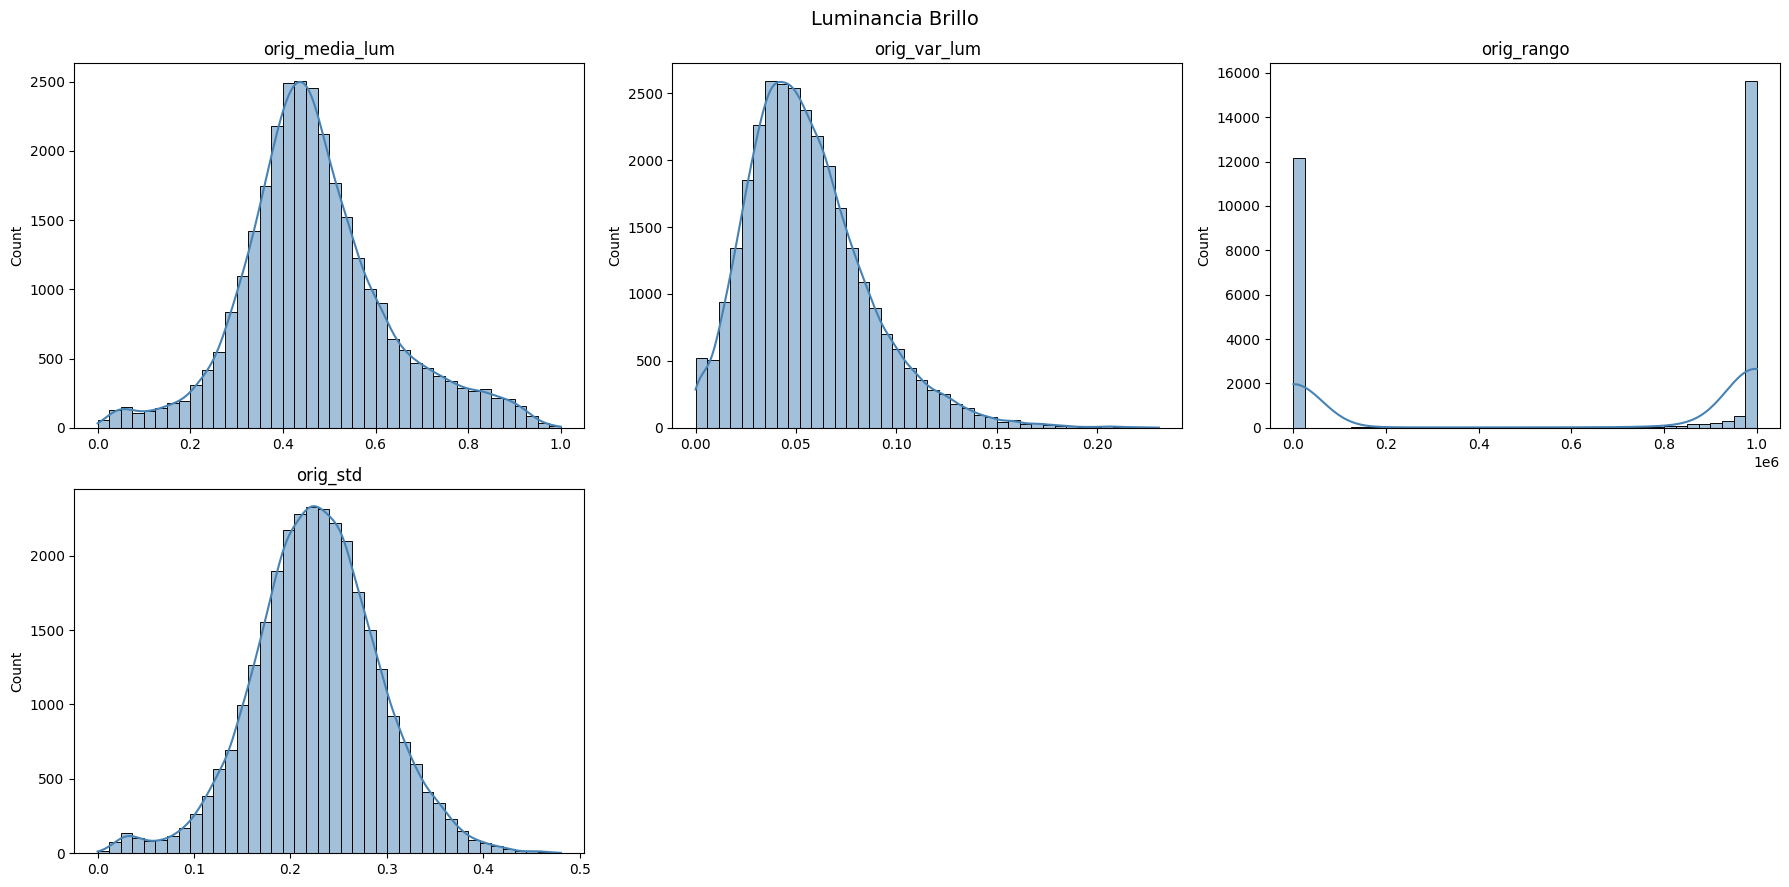

Guardado: csv/eda_outputs/dist_01a_luminancia_brillo.png


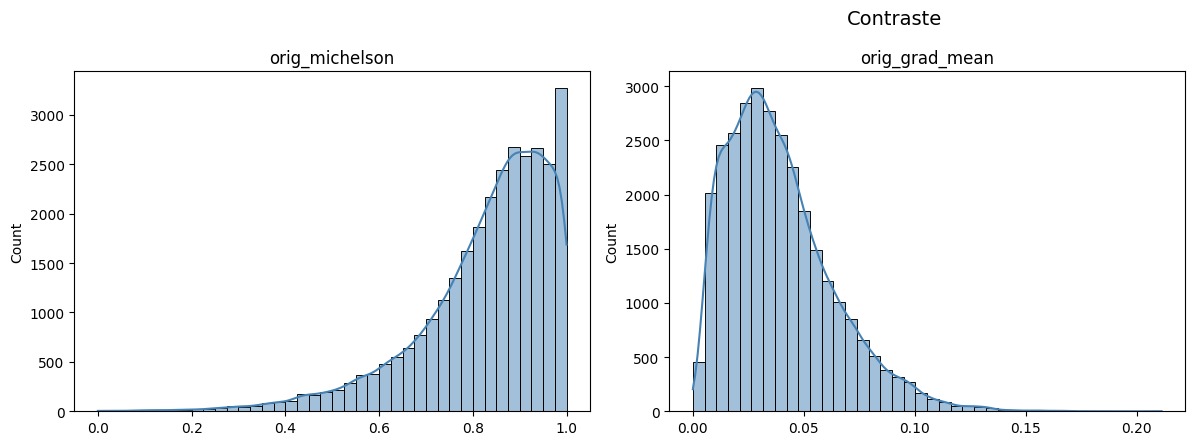

Guardado: csv/eda_outputs/dist_01b_contraste.png


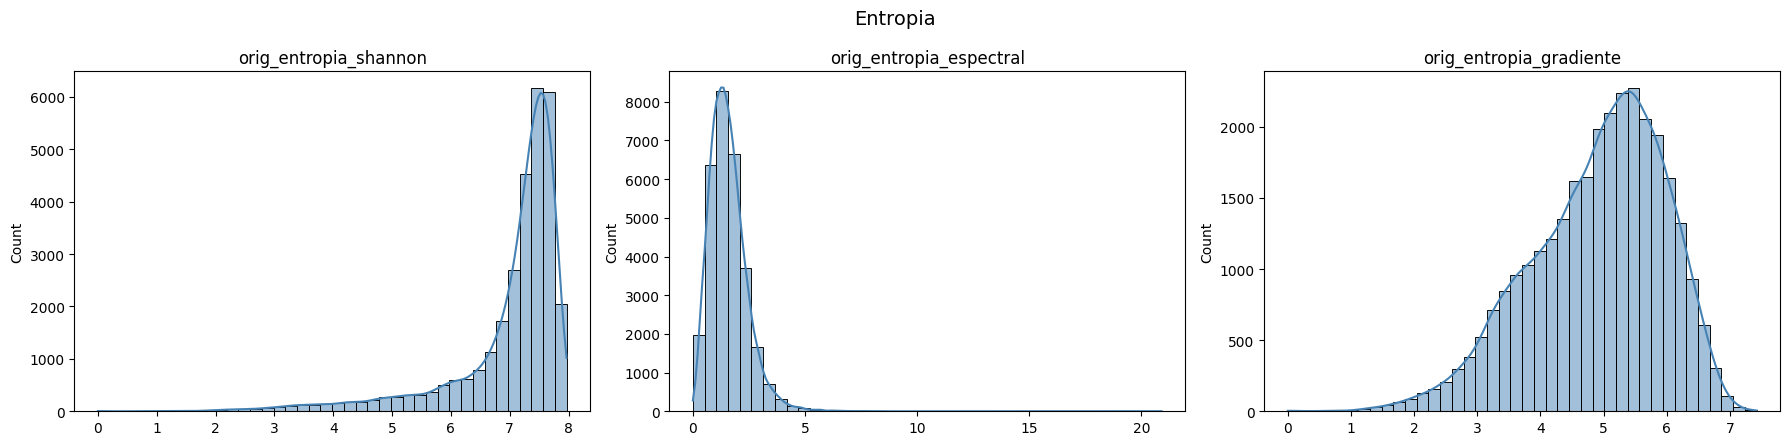

Guardado: csv/eda_outputs/dist_01c_entropia.png


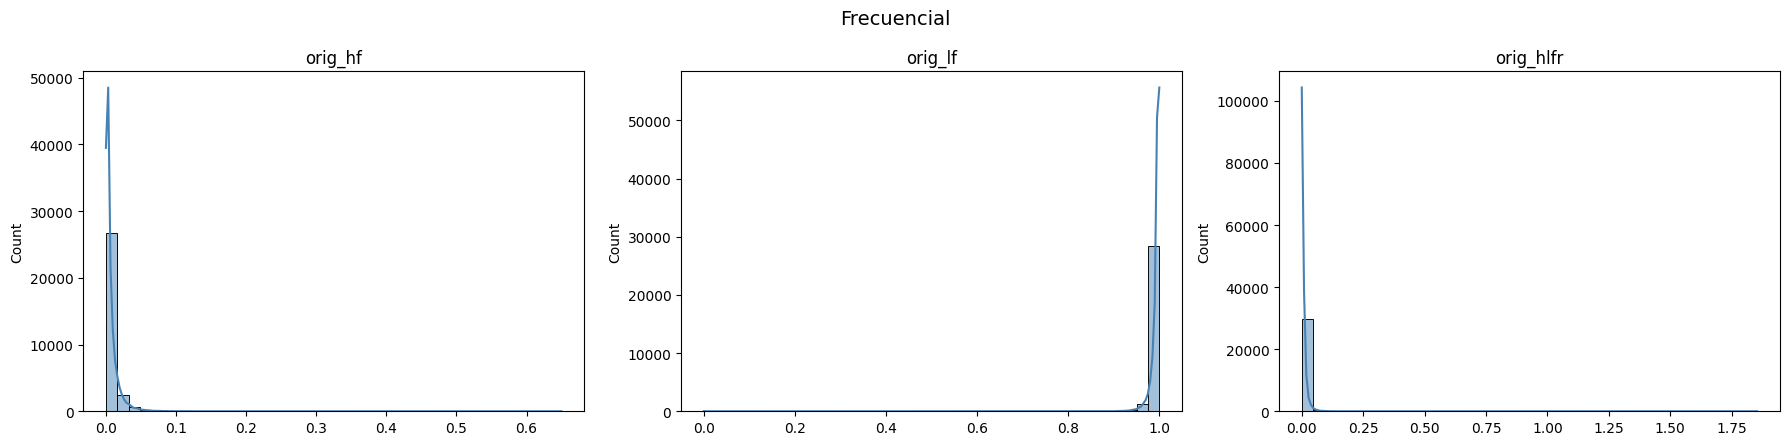

Guardado: csv/eda_outputs/dist_01d_frecuencial.png


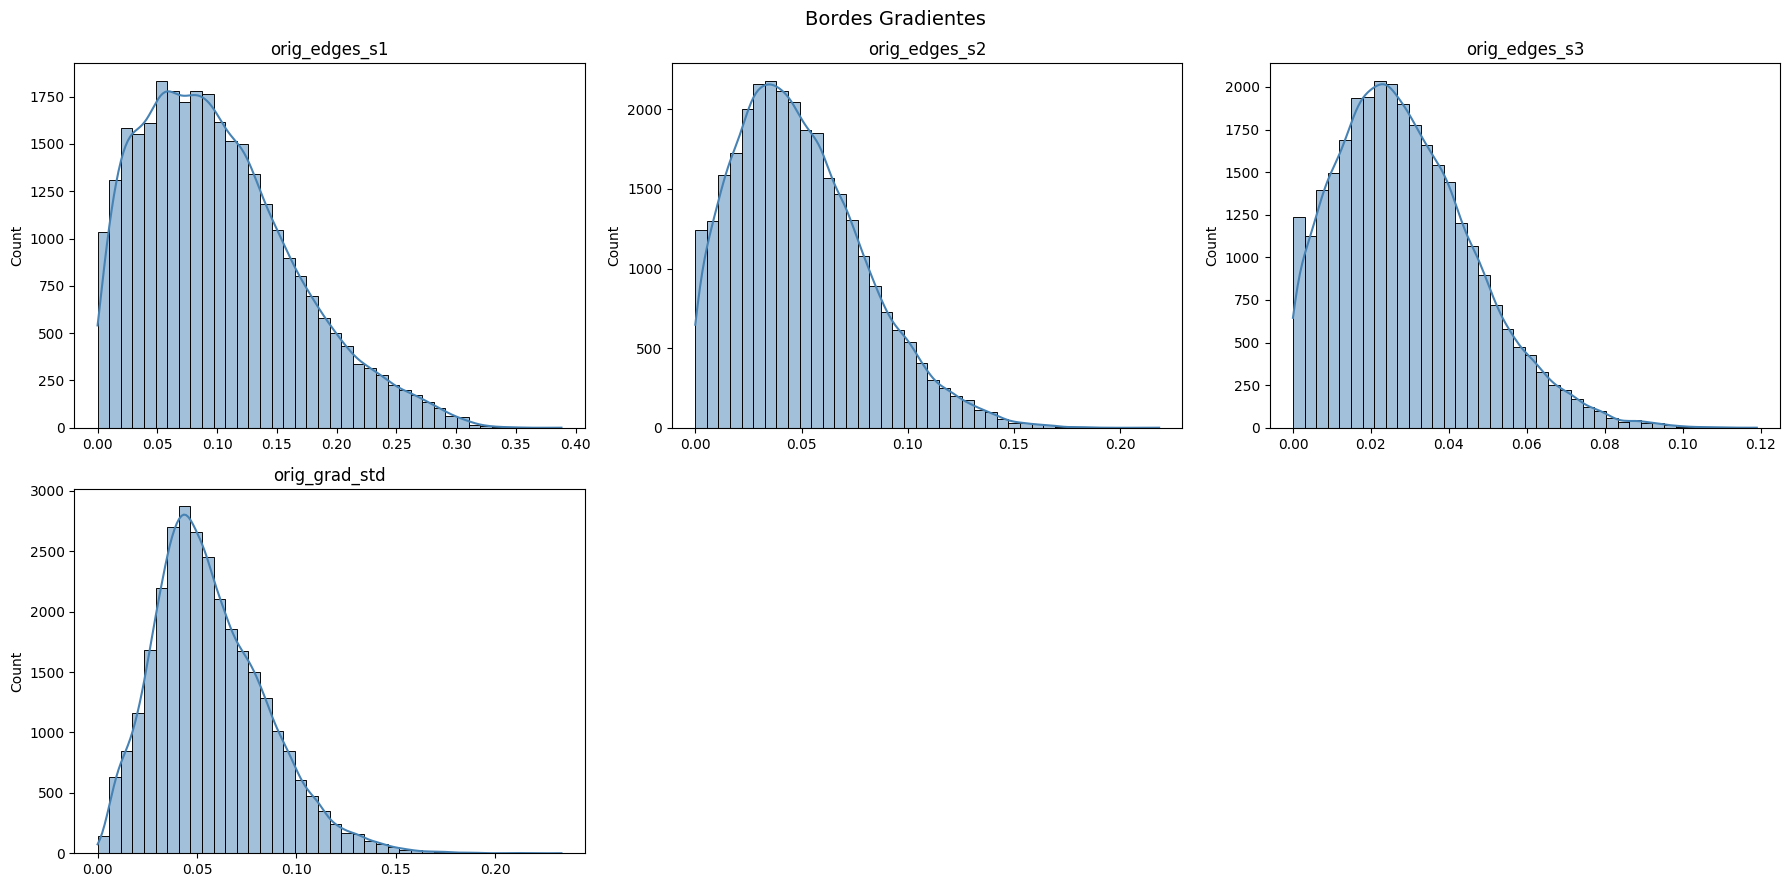

Guardado: csv/eda_outputs/dist_01e_bordes_gradientes.png


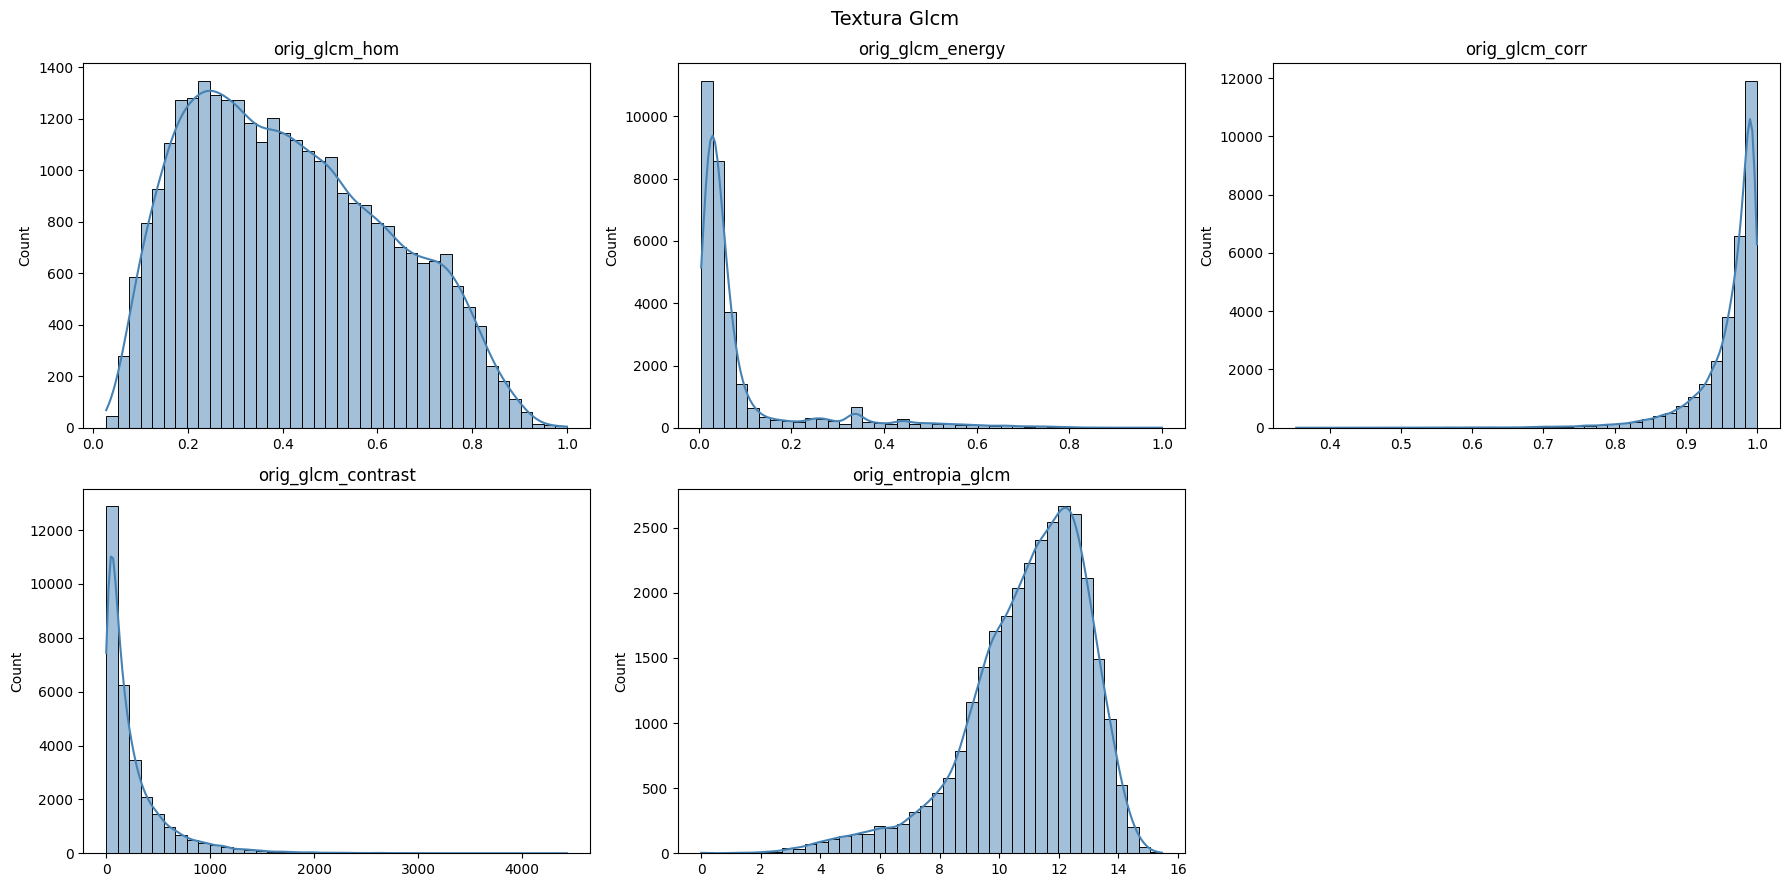

Guardado: csv/eda_outputs/dist_01f_textura_glcm.png


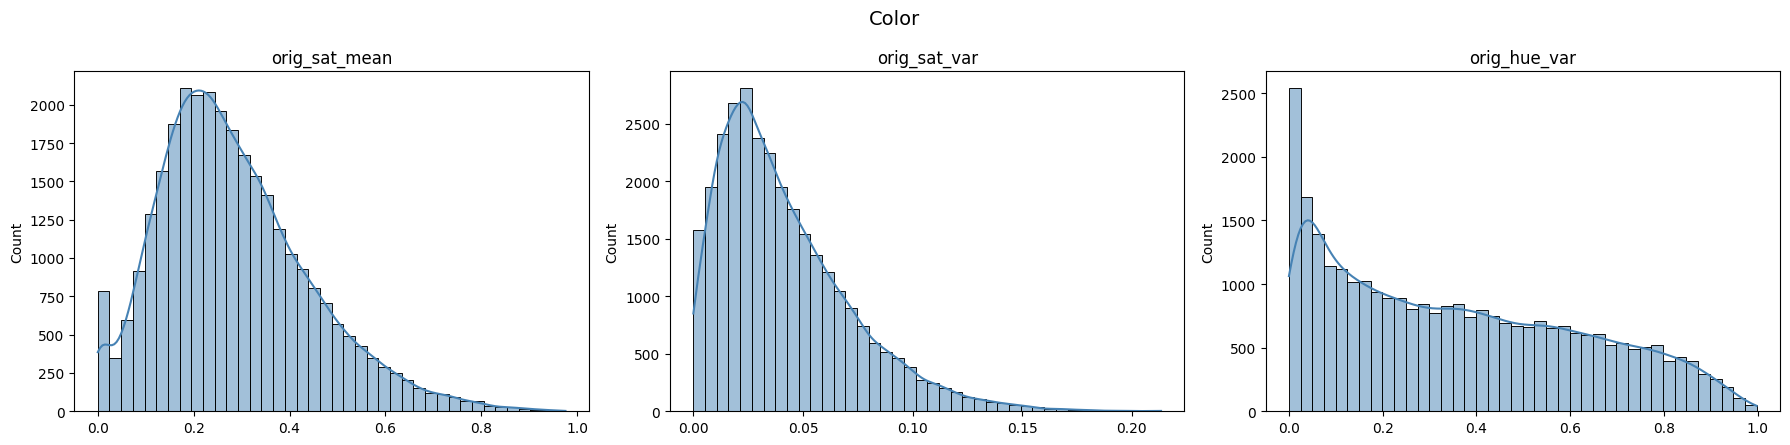

Guardado: csv/eda_outputs/dist_01g_color.png


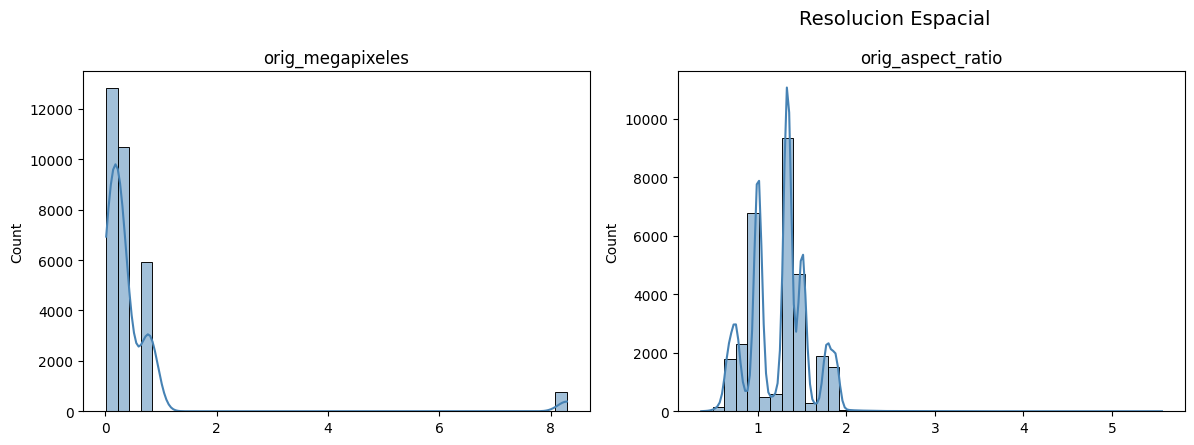

Guardado: csv/eda_outputs/dist_01h_resolucion_espacial.png


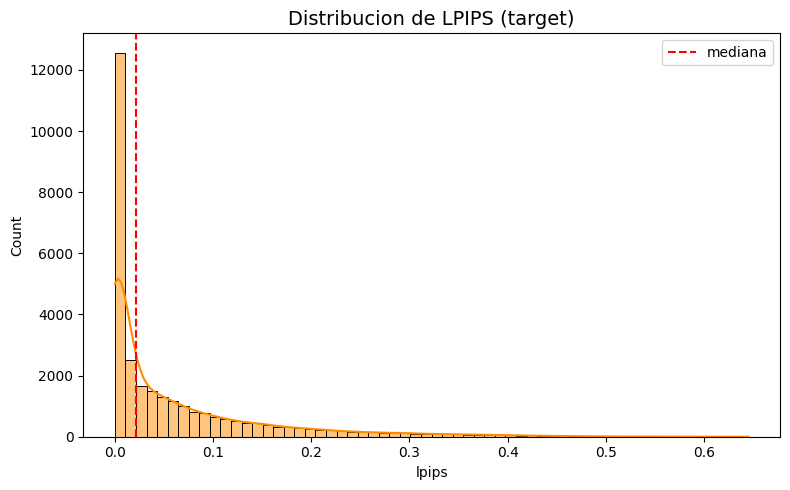

Guardado: csv/eda_outputs/dist_07_target_lpips.png


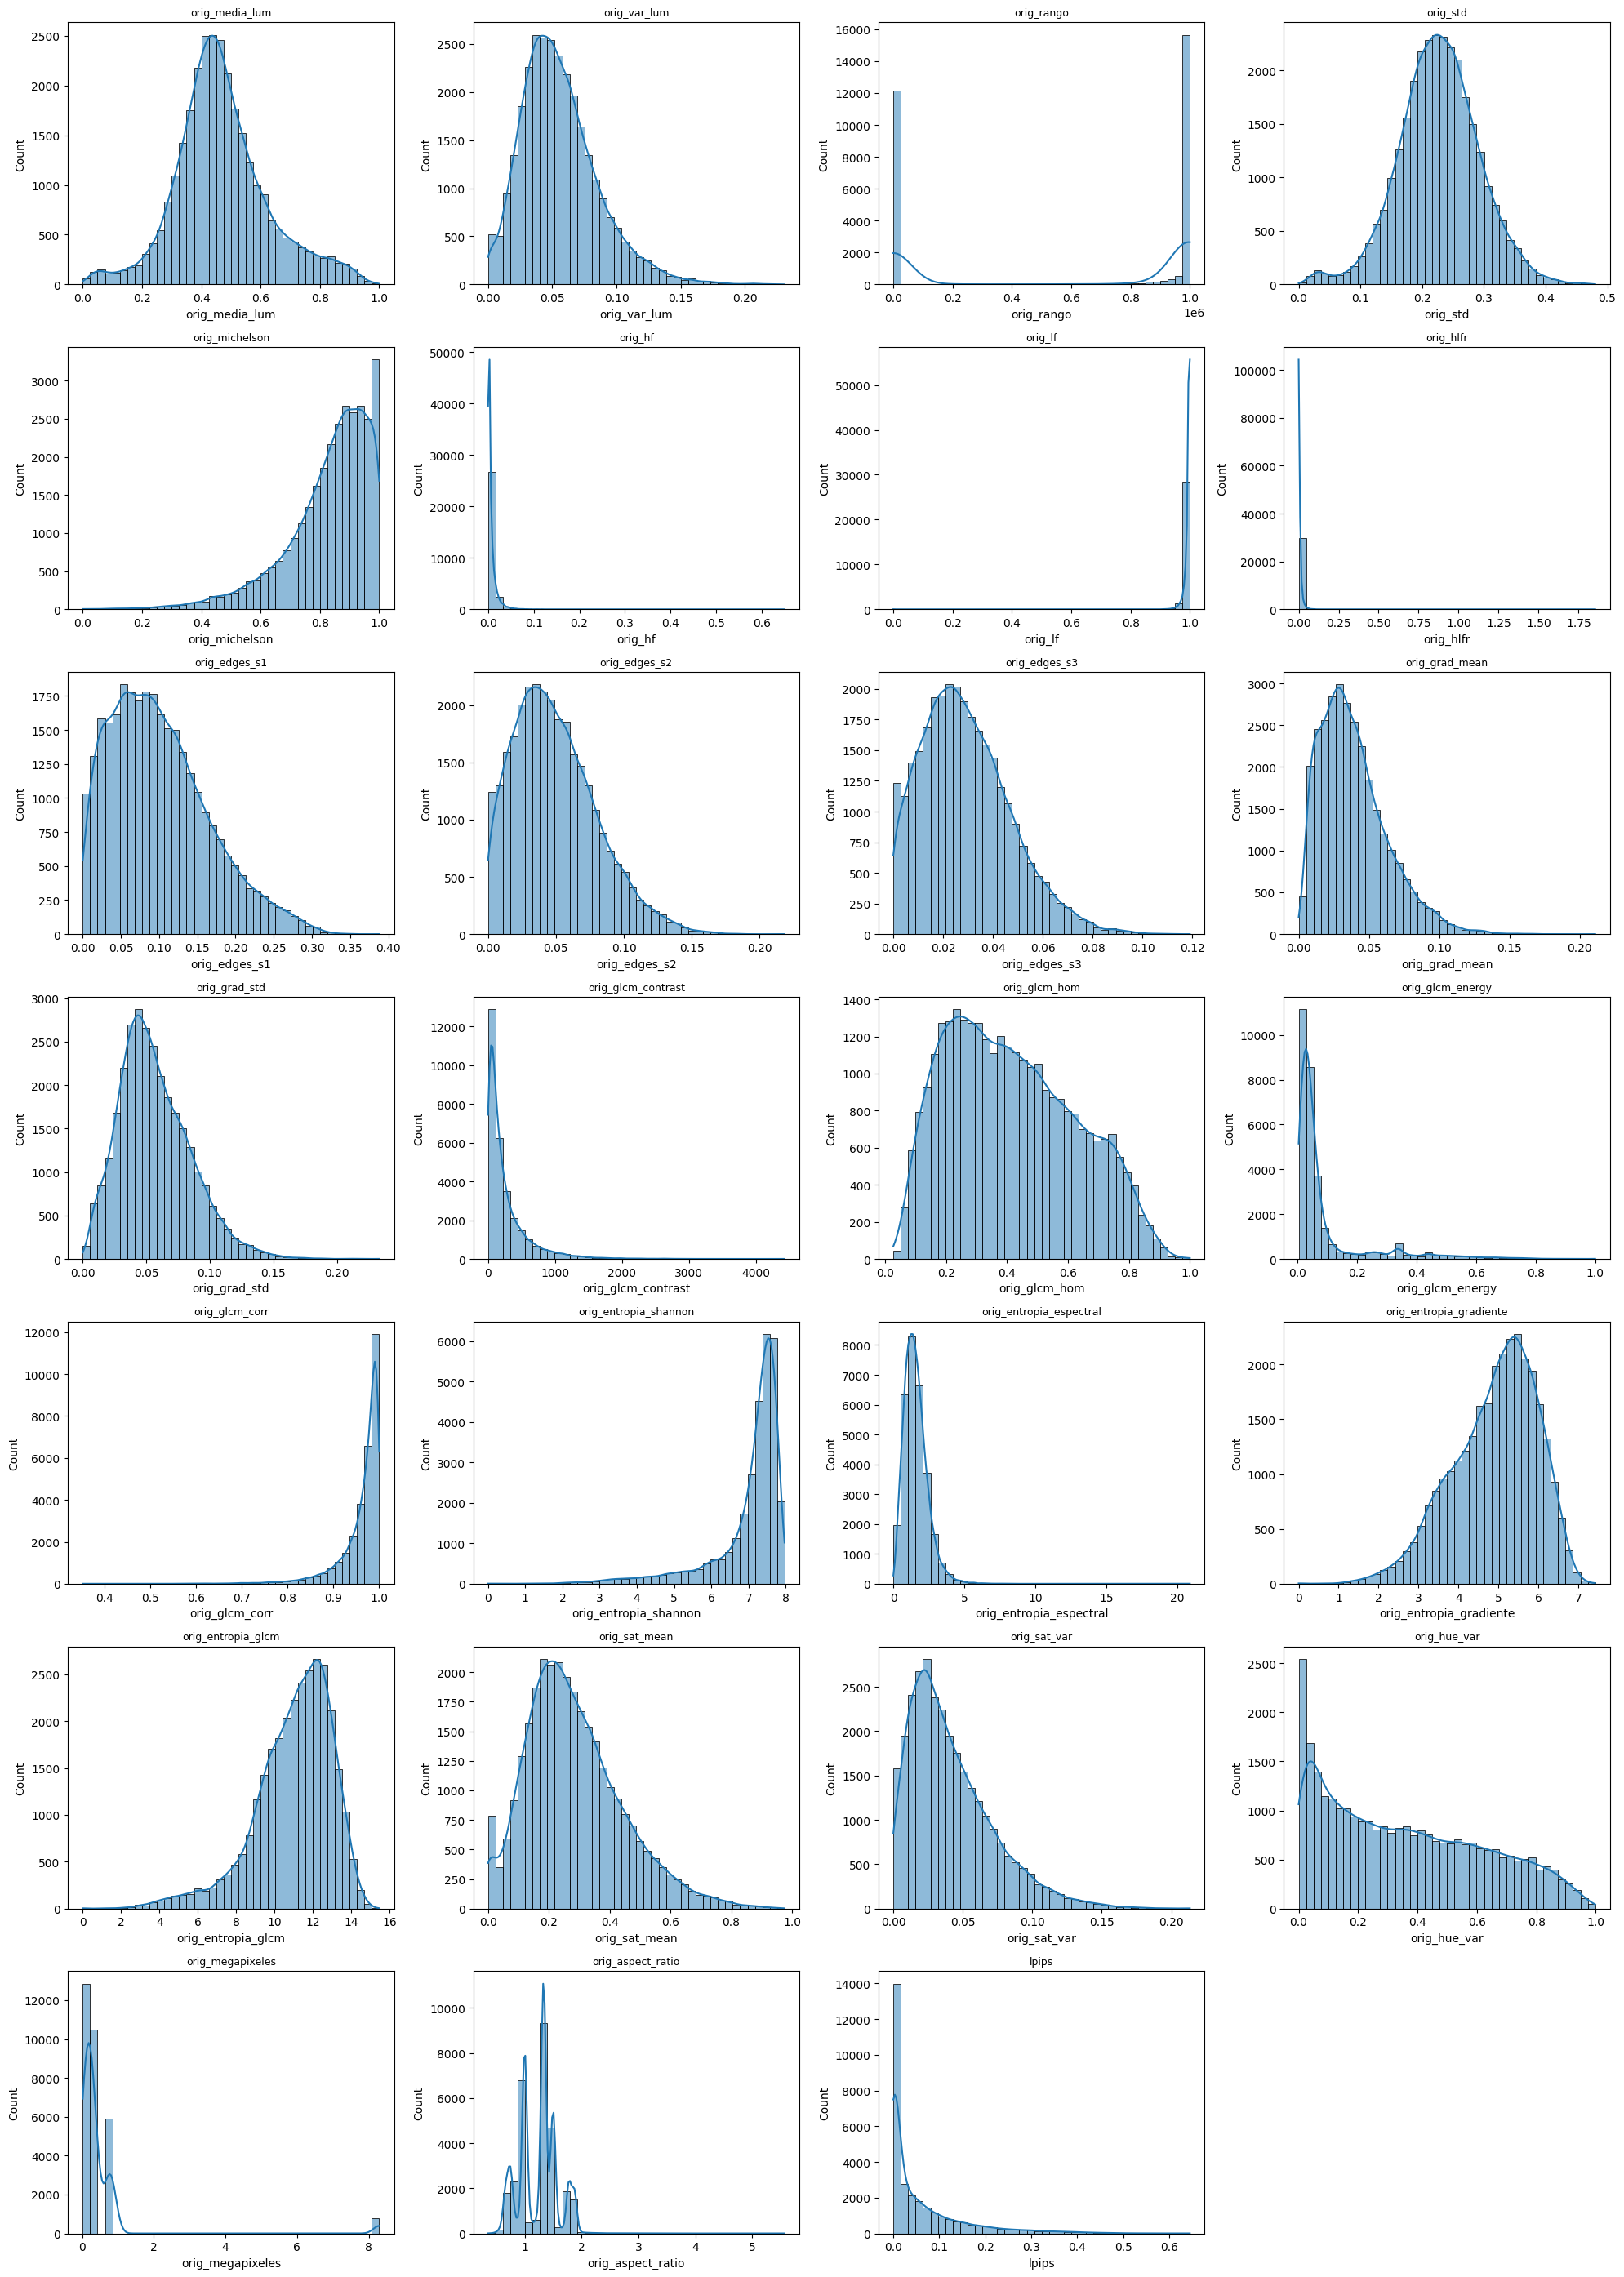

Guardado (anexo): csv/eda_outputs/dist_anexo_todas_las_variables.png


In [6]:
print("=" * 70)
print("3. DISTRIBUCIONES UNIVARIADAS (por grupos tematicos)")
print("=" * 70)
 
# Grupos tematicos, en el mismo orden usado en el analisis descriptivo.
# Esto evita una cuadricula unica de 28 graficas ilegible en el documento;
# cada grupo se guarda como una figura independiente, mas grande y clara.
#   a. Luminancia y brillo | b. Contraste | c. Entropia | d. Frecuencial
#   e. Bordes y gradientes | f. Textura (GLCM) | g. Color | h. Resolucion espacial
grupos = {
    "01a_luminancia_brillo": ["orig_media_lum", "orig_var_lum",
                               "orig_rango", "orig_std"],
    "01b_contraste": ["orig_michelson", "orig_grad_mean"],
    "01c_entropia": ["orig_entropia_shannon", "orig_entropia_espectral",
                      "orig_entropia_gradiente"],
    "01d_frecuencial": ["orig_hf", "orig_lf", "orig_hlfr"],
    "01e_bordes_gradientes": ["orig_edges_s1", "orig_edges_s2",
                               "orig_edges_s3", "orig_grad_std"],
    "01f_textura_glcm": ["orig_glcm_hom", "orig_glcm_energy",
                          "orig_glcm_corr", "orig_glcm_contrast",
                          "orig_entropia_glcm"],
    "01g_color": ["orig_sat_mean", "orig_sat_var", "orig_hue_var"],
    "01h_resolucion_espacial": ["orig_megapixeles", "orig_aspect_ratio"],
}
 
def graficar_grupo(nombre, columnas, n_cols=3):
    """Genera una figura con histogramas+KDE para un grupo de columnas."""
    n_rows = int(np.ceil(len(columnas) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows))
    axes = np.atleast_1d(axes).ravel()
 
    for i, col in enumerate(columnas):
        sns.histplot(df[col].dropna(), kde=True, ax=axes[i], bins=40,
                     color="steelblue")
        axes[i].set_title(col, fontsize=12)
        axes[i].set_xlabel("")
 
    for j in range(len(columnas), len(axes)):
        fig.delaxes(axes[j])
 
    fig.suptitle(nombre.split("_", 1)[1].replace("_", " ").title(), fontsize=14)
    plt.tight_layout()
    ruta = f"{OUT_DIR}/dist_{nombre}.png"
    plt.savefig(ruta, dpi=150)
    plt.show()
    print(f"Guardado: {ruta}")
 
for nombre, columnas in grupos.items():
    graficar_grupo(nombre, columnas)
 
# El target (lpips) va en su propia figura individual, mas grande,
# por ser la variable mas importante del documento.
plt.figure(figsize=(8, 5))
sns.histplot(df[target].dropna(), kde=True, bins=60, color="darkorange")
plt.axvline(df[target].median(), color="red", linestyle="--", label="mediana")
plt.title("Distribucion de LPIPS (target)", fontsize=14)
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/dist_07_target_lpips.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/dist_07_target_lpips.png")
 
# (Opcional) cuadricula completa de todas las variables, util solo como
# anexo/apendice del documento, no para el cuerpo principal.
cols_a_graficar = features_img + [target]
n_cols_grid = 4
n_rows_grid = int(np.ceil(len(cols_a_graficar) / n_cols_grid))
fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(20, 4 * n_rows_grid))
axes = axes.ravel()
for i, col in enumerate(cols_a_graficar):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], bins=40)
    axes[i].set_title(col, fontsize=9)
for j in range(len(cols_a_graficar), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/dist_anexo_todas_las_variables.png", dpi=130)
plt.show()
print(f"Guardado (anexo): {OUT_DIR}/dist_anexo_todas_las_variables.png")

In [ ]:
from PIL import Image
# Verificar si los picos de megapixeles corresponden a resoluciones estándar
anchos_altos = df["img_original"].apply(lambda p: Image.open(p).size)  # requiere Pillow
resoluciones = anchos_altos.value_counts().head(10)
print(resoluciones)

img_original
(1024, 768)     4065
(256, 256)      3661
(640, 480)      2122
(1200, 640)     1444
(512, 512)      1345
(640, 427)      1219
(298, 224)      1056
(500, 375)       987
(3840, 2160)     764
(600, 400)       761
Name: count, dtype: int64


In [9]:
print(df["orig_megapixeles"].round(3).value_counts().head(10))
print(df["orig_aspect_ratio"].round(2).value_counts().head(10))

orig_megapixeles
0.786    4466
0.066    3727
0.307    2924
0.273    2184
0.768    1444
0.262    1365
0.188    1361
0.067    1354
0.166     864
0.240     774
Name: count, dtype: int64
orig_aspect_ratio
1.33    8638
1.00    6365
1.50    3490
0.75    1770
1.78    1705
1.88    1452
0.67    1000
1.51     544
0.66     227
1.34     193
Name: count, dtype: int64


In [16]:
# Verificación de la relación matemática entre hf y lf

pares_hf_lf = df[["orig_hf", "orig_lf"]].dropna().copy()

suma_hf_lf = pares_hf_lf["orig_hf"] + pares_hf_lf["orig_lf"]

print("=" * 70)
print("VERIFICACIÓN DE LA RELACIÓN orig_hf + orig_lf = 1")
print("=" * 70)

print(f"Observaciones analizadas: {len(pares_hf_lf):,}")
print(f"Mínimo de hf + lf: {suma_hf_lf.min():.12f}")
print(f"Máximo de hf + lf: {suma_hf_lf.max():.12f}")
print(f"Media de hf + lf:   {suma_hf_lf.mean():.12f}")

print("\nDesviación respecto a 1:")
print(f"Máxima desviación: {(suma_hf_lf - 1).abs().max():.12e}")
print(f"Media desviación:  {(suma_hf_lf - 1).abs().mean():.12e}")

r_hf_lf = pares_hf_lf["orig_hf"].corr(pares_hf_lf["orig_lf"])

print(f"\nPearson entre orig_hf y orig_lf: {r_hf_lf:.12f}")

# Número de observaciones que no cumplen la relación
incumplen = ~np.isclose(
    suma_hf_lf,
    1.0,
    rtol=1e-10,
    atol=1e-10
)

print(f"Observaciones que no cumplen hf + lf = 1: {incumplen.sum():,}")
print(f"Porcentaje: {incumplen.mean() * 100:.4f} %")

VERIFICACIÓN DE LA RELACIÓN orig_hf + orig_lf = 1
Observaciones analizadas: 29,991
Mínimo de hf + lf: 0.000000000000
Máximo de hf + lf: 1.000000000000
Media de hf + lf:   0.999866626655

Desviación respecto a 1:
Máxima desviación: 1.000000000000e+00
Media desviación:  1.333733453372e-04

Pearson entre orig_hf y orig_lf: -0.669815338725
Observaciones que no cumplen hf + lf = 1: 4
Porcentaje: 0.0133 %


In [ ]:
casos_no_complementarios = df[
    ~np.isclose(
        df["orig_hf"] + df["orig_lf"],
        1.0,
        rtol=1e-10,
        atol=1e-10
    )
][[
    "img_original",
    "orig_hf",
    "orig_lf"
]].copy()

print(casos_no_complementarios.to_string(index=False))

print("\nSuma hf + lf:")
casos_no_complementarios["suma_hf_lf"] = (
    casos_no_complementarios["orig_hf"] +
    casos_no_complementarios["orig_lf"]
)

print(casos_no_complementarios.to_string(index=False))

            img_original  orig_hf  orig_lf
imagenes\png\243 (2).png      0.0      0.0
imagenes\png\304 (2).png      0.0      0.0
imagenes\png\664 (2).png      0.0      0.0
    imagenes\png\664.png      0.0      0.0

Suma hf + lf:
            img_original  orig_hf  orig_lf  suma_hf_lf
imagenes\png\243 (2).png      0.0      0.0         0.0
imagenes\png\304 (2).png      0.0      0.0         0.0
imagenes\png\664 (2).png      0.0      0.0         0.0
    imagenes\png\664.png      0.0      0.0         0.0


# CELDA 4 — DISTRIBUCION DETALLADA DEL TARGET (lpips)

4. DISTRIBUCION DE LPIPS (target)


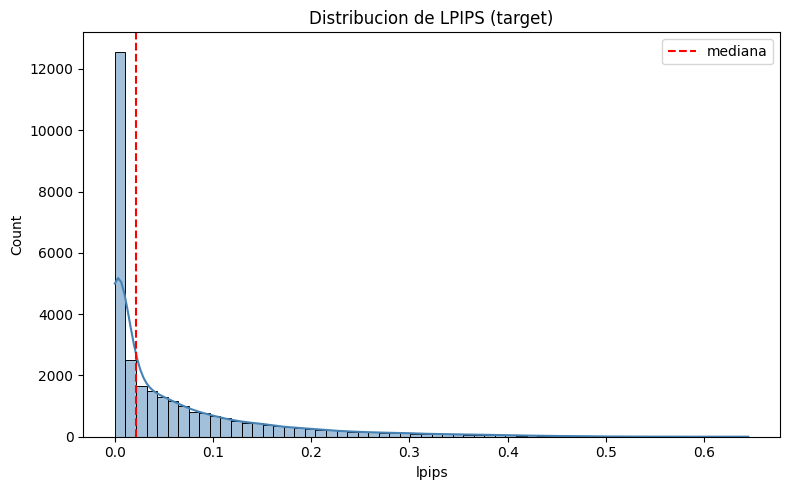

Guardado: csv/eda_outputs/distribucion_lpips.png
count    29989.000000
mean         0.061067
std          0.089035
min          0.000000
50%          0.021126
90%          0.182943
95%          0.258648
99%          0.394983
max          0.645018


In [10]:
print("=" * 70)
print("4. DISTRIBUCION DE LPIPS (target)")
print("=" * 70)
plt.figure(figsize=(8, 5))
sns.histplot(df[target].dropna(), kde=True, bins=60, color="steelblue")
plt.axvline(df[target].median(), color="red", linestyle="--", label="mediana")
plt.title("Distribucion de LPIPS (target)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/distribucion_lpips.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/distribucion_lpips.png")
print(df[target].describe(percentiles=[.5, .9, .95, .99]).to_string())

# CELDA 5 — DISTRIBUCION DE VARIABLES CATEGORICAS

5. DISTRIBUCION DE CATEGORICAS


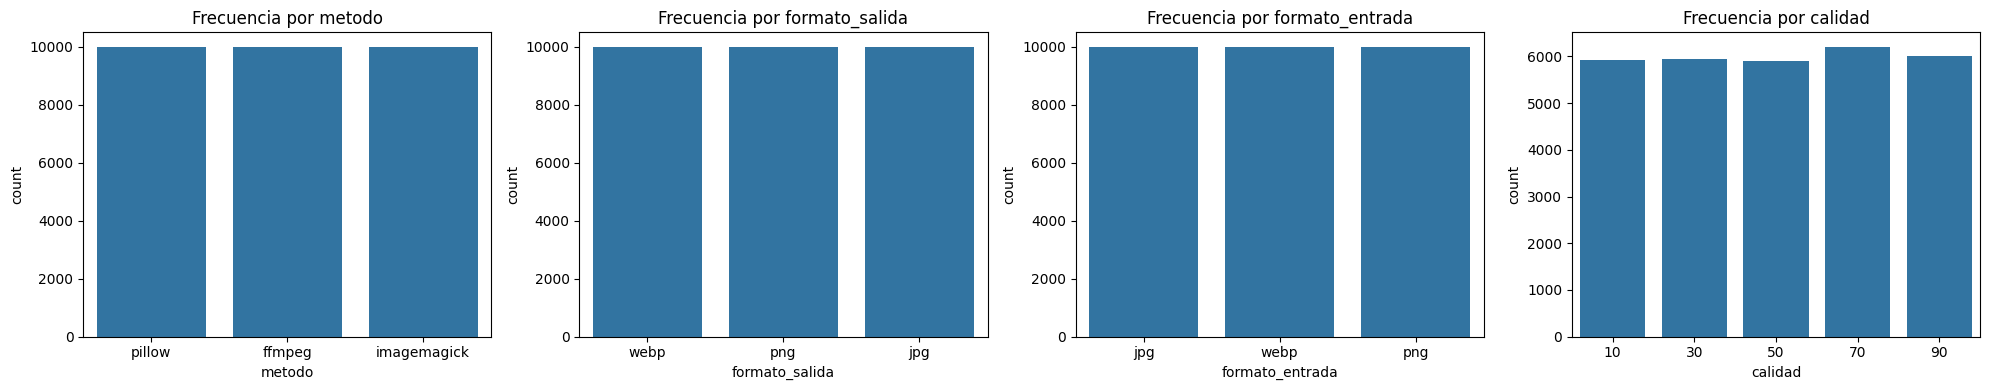

Guardado: csv/eda_outputs/distribucion_categoricas.png


In [12]:
print("=" * 70)
print("5. DISTRIBUCION DE CATEGORICAS")
print("=" * 70)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
sns.countplot(data=df, x="metodo", ax=axes[0])
axes[0].set_title("Frecuencia por metodo")
sns.countplot(data=df, x="formato_salida", ax=axes[1])
axes[1].set_title("Frecuencia por formato_salida")
sns.countplot(data=df, x="formato_entrada", ax=axes[2])
axes[2].set_title("Frecuencia por formato_entrada")
sns.countplot(data=df, x="calidad", ax=axes[3])
axes[3].set_title("Frecuencia por calidad")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/distribucion_categoricas.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/distribucion_categoricas.png")

# CELDA 6 — ANALISIS COMBINADO: lpips vs metodo / formato / calidad

6. LPIPS SEGUN METODO / FORMATO / CALIDAD


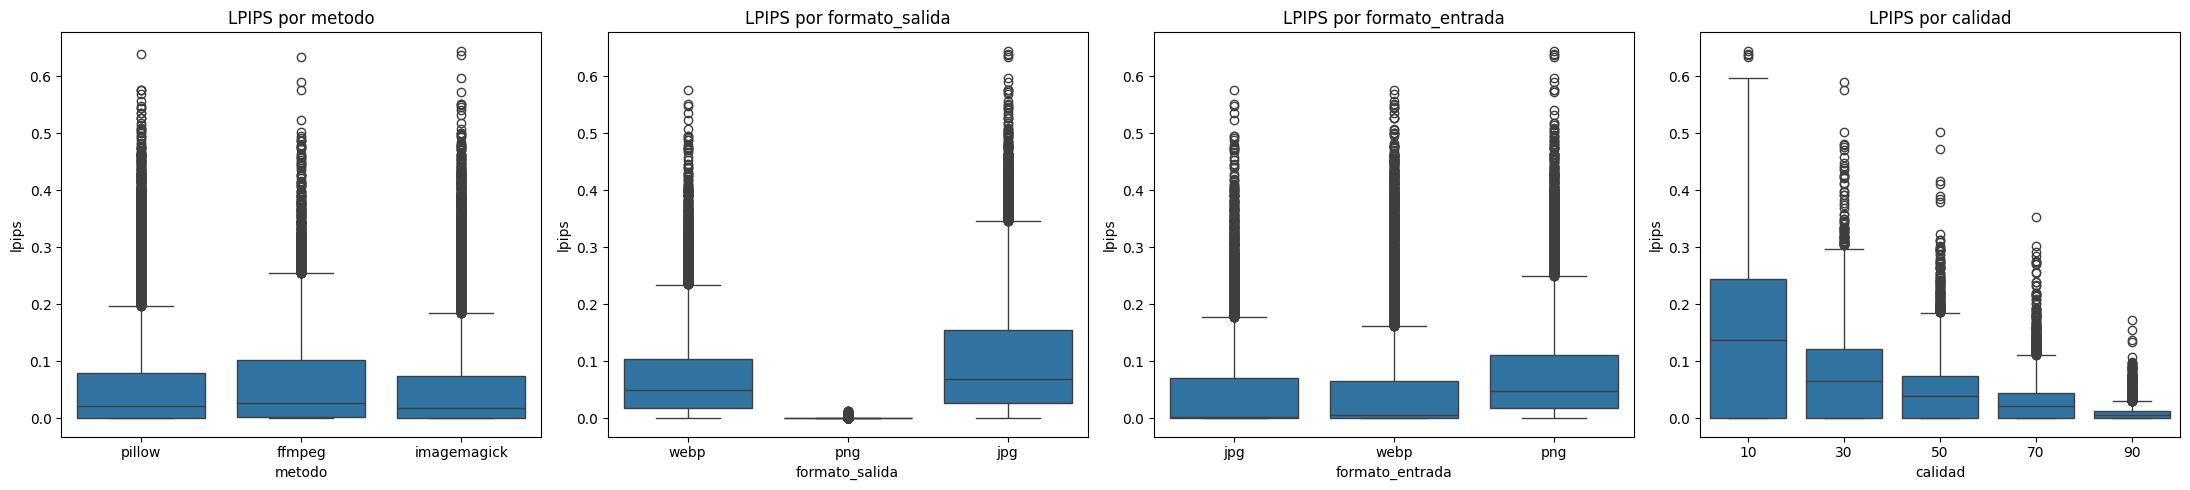

Guardado: csv/eda_outputs/lpips_por_categoria.png

LPIPS promedio por combinacion metodo x calidad:
calidad            10        30        50        70        90
metodo                                                       
ffmpeg       0.126566  0.088834  0.062122  0.039471  0.012918
imagemagick  0.152105  0.066790  0.042418  0.024371  0.006590
pillow       0.156796  0.068418  0.041879  0.024851  0.007341


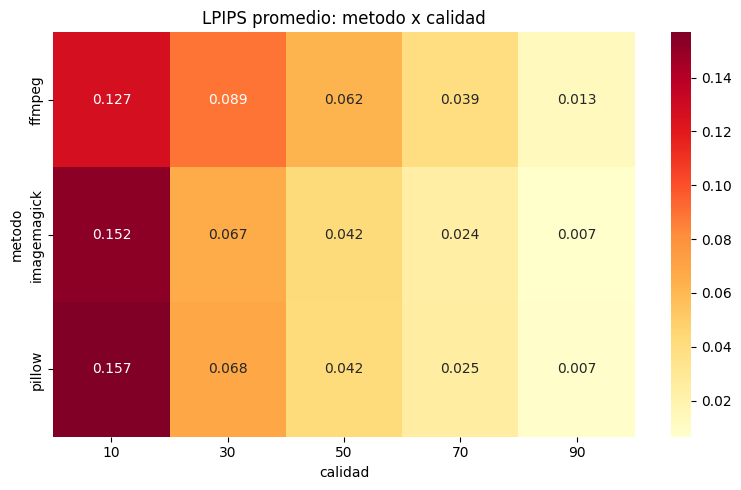

Guardado: csv/eda_outputs/heatmap_lpips_metodo_calidad.png

LPIPS promedio por combinacion formato_salida x calidad:
calidad               10        30        50        70        90
formato_salida                                                  
jpg             0.270699  0.129895  0.080013  0.047025  0.015166
png             0.000417  0.000483  0.000507  0.000466  0.000492
webp            0.165984  0.094342  0.064324  0.042662  0.011093


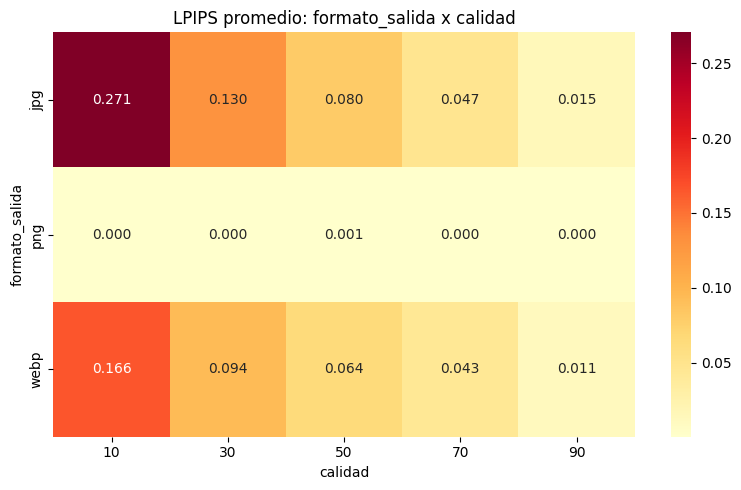

Guardado: csv/eda_outputs/heatmap_lpips_formato_calidad.png

LPIPS promedio por combinacion formato_entrada x formato_salida:
formato_salida        jpg       png      webp
formato_entrada                              
jpg                   NaN  0.000052  0.094762
png              0.109037       NaN  0.055708
webp             0.106035  0.000894       NaN


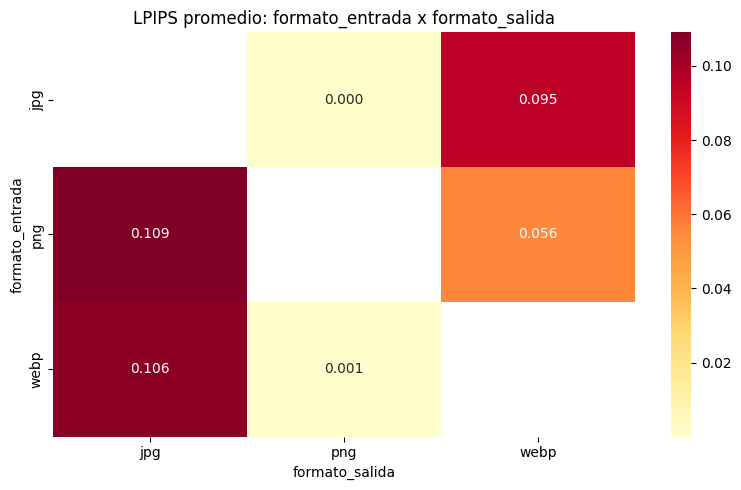

Guardado: csv/eda_outputs/heatmap_lpips_entrada_salida.png


In [10]:
print("=" * 70)
print("6. LPIPS SEGUN METODO / FORMATO / CALIDAD")
print("=" * 70)
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
sns.boxplot(data=df, x="metodo", y=target, ax=axes[0])
axes[0].set_title("LPIPS por metodo")
sns.boxplot(data=df, x="formato_salida", y=target, ax=axes[1])
axes[1].set_title("LPIPS por formato_salida")
sns.boxplot(data=df, x="formato_entrada", y=target, ax=axes[2])
axes[2].set_title("LPIPS por formato_entrada")
sns.boxplot(data=df, x="calidad", y=target, ax=axes[3])
axes[3].set_title("LPIPS por calidad")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/lpips_por_categoria.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/lpips_por_categoria.png")
 
print("\nLPIPS promedio por combinacion metodo x calidad:")
pivot = df.pivot_table(values=target, index="metodo", columns="calidad", aggfunc="mean")
print(pivot.to_string())
 
plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlOrRd")
plt.title("LPIPS promedio: metodo x calidad")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/heatmap_lpips_metodo_calidad.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/heatmap_lpips_metodo_calidad.png")
 
print("\nLPIPS promedio por combinacion formato_salida x calidad:")
pivot2 = df.pivot_table(values=target, index="formato_salida", columns="calidad", aggfunc="mean")
print(pivot2.to_string())
 
plt.figure(figsize=(8, 5))
sns.heatmap(pivot2, annot=True, fmt=".3f", cmap="YlOrRd")
plt.title("LPIPS promedio: formato_salida x calidad")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/heatmap_lpips_formato_calidad.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/heatmap_lpips_formato_calidad.png")
 
print("\nLPIPS promedio por combinacion formato_entrada x formato_salida:")
pivot3 = df.pivot_table(values=target, index="formato_entrada", columns="formato_salida", aggfunc="mean")
print(pivot3.to_string())
 
plt.figure(figsize=(8, 5))
sns.heatmap(pivot3, annot=True, fmt=".3f", cmap="YlOrRd")
plt.title("LPIPS promedio: formato_entrada x formato_salida")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/heatmap_lpips_entrada_salida.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/heatmap_lpips_entrada_salida.png")
 

# CELDA 7 — MATRIZ DE CORRELACION COMPLETA

7. MATRIZ DE CORRELACION


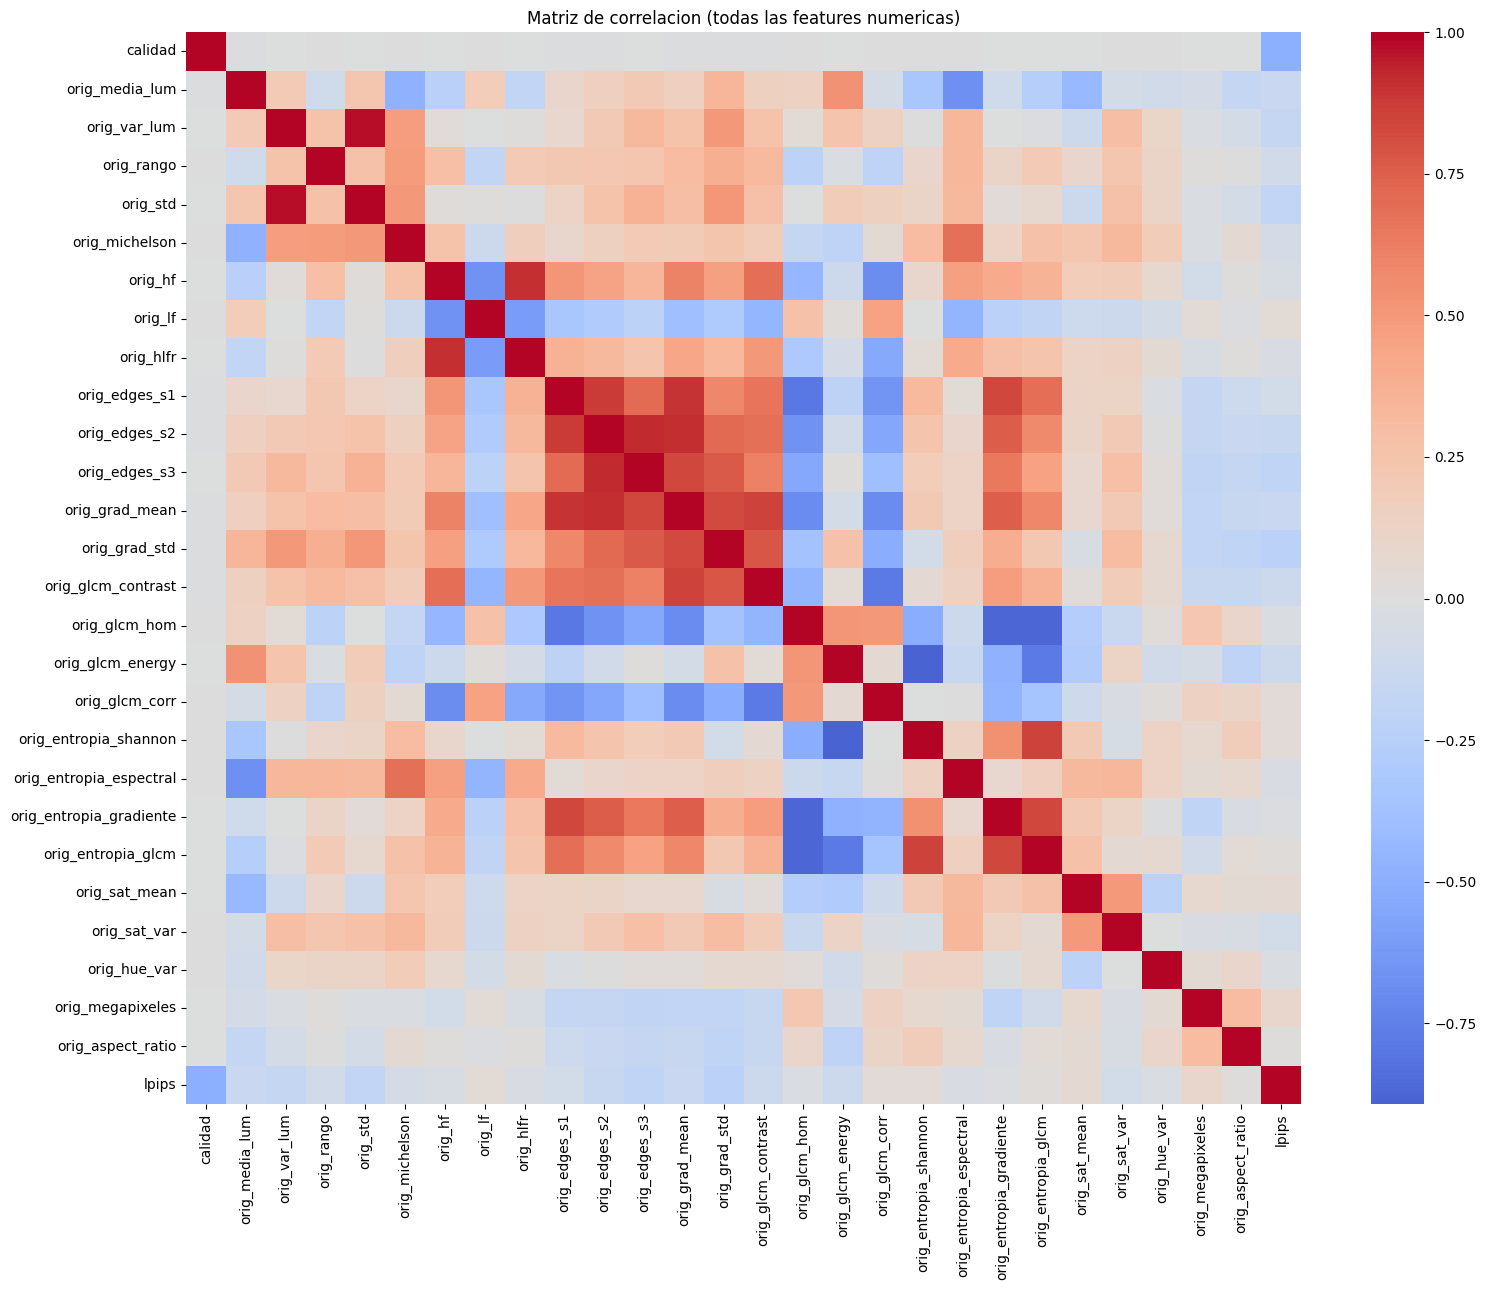

Guardado: csv/eda_outputs/heatmap_correlacion_completa.png


In [8]:
print("=" * 70)
print("7. MATRIZ DE CORRELACION")
print("=" * 70)
corr = df[num_cols].corr()
 
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=True, yticklabels=True)
plt.title("Matriz de correlacion (todas las features numericas)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/heatmap_correlacion_completa.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/heatmap_correlacion_completa.png")

# CELDA 8 — CORRELACION DE CADA FEATURE CON EL TARGET

8. CORRELACION DE CADA FEATURE CON LPIPS
calidad                   -0.503457
orig_grad_std             -0.227866
orig_edges_s3             -0.198184
orig_std                  -0.179057
orig_var_lum              -0.161594
orig_edges_s2             -0.152196
orig_media_lum            -0.142868
orig_grad_mean            -0.139484
orig_glcm_contrast        -0.122027
orig_glcm_energy          -0.120695
orig_rango                -0.091151
orig_megapixeles           0.086310
orig_edges_s1             -0.083959
orig_sat_var              -0.081574
orig_michelson            -0.066065
orig_sat_mean              0.060382
orig_hf                   -0.048347
orig_lf                    0.041718
orig_entropia_shannon      0.037284
orig_hlfr                 -0.036829
orig_entropia_espectral   -0.035974
orig_glcm_corr             0.031770
orig_glcm_hom             -0.027101
orig_hue_var              -0.024894
orig_entropia_gradiente   -0.018392
orig_entropia_glcm         0.017523
orig_aspect_ratio      

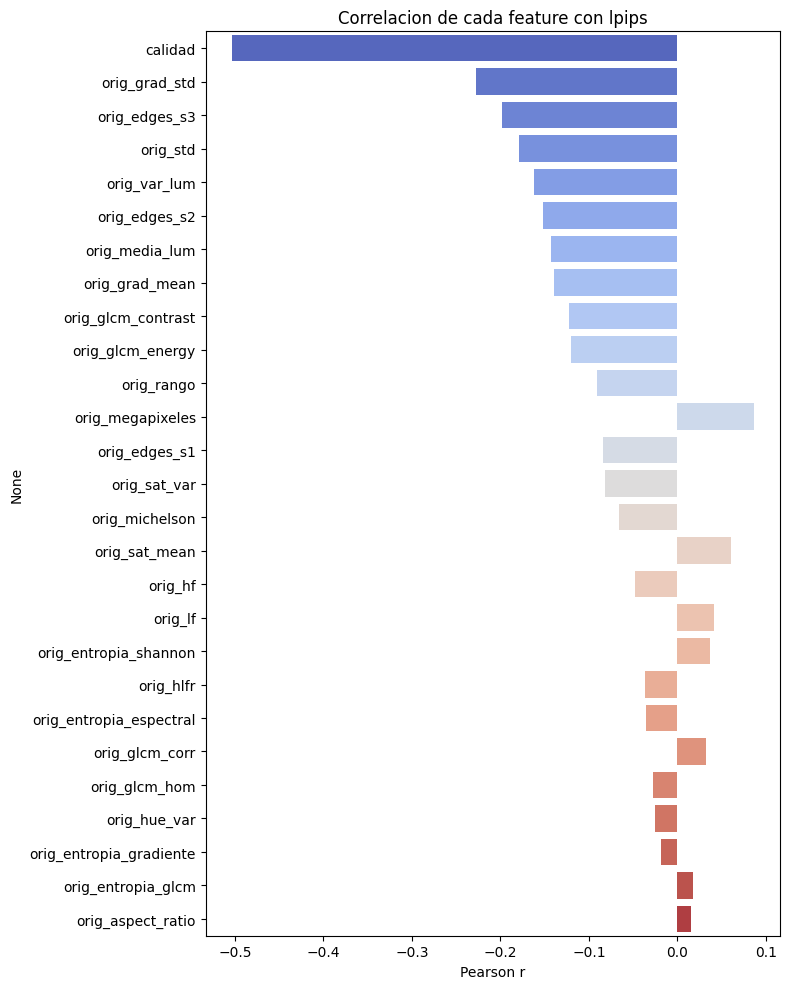

Guardado: csv/eda_outputs/barplot_correlacion_target.png


In [9]:
print("=" * 70)
print("8. CORRELACION DE CADA FEATURE CON LPIPS")
print("=" * 70)
corr_target = corr[target].drop(target).sort_values(key=abs, ascending=False)
print(corr_target.to_string())
corr_target.to_csv(f"{OUT_DIR}/correlacion_con_target.csv")
 
plt.figure(figsize=(8, 10))
sns.barplot(x=corr_target.values, y=corr_target.index, hue=corr_target.index,
            palette="coolwarm", legend=False)
plt.title(f"Correlacion de cada feature con {target}")
plt.xlabel("Pearson r")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/barplot_correlacion_target.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/barplot_correlacion_target.png")

# CELDA 9 — MULTICOLINEALIDAD ENTRE FEATURES

In [10]:
print("=" * 70)
print("9. PARES DE FEATURES CON MULTICOLINEALIDAD ALTA (|r| > 0.9)")
print("=" * 70)
cols_feat = [c for c in num_cols if c != target]
alta_corr = []
for i in range(len(cols_feat)):
    for j in range(i + 1, len(cols_feat)):
        r = corr.loc[cols_feat[i], cols_feat[j]]
        if abs(r) > 0.9:
            alta_corr.append((cols_feat[i], cols_feat[j], r))
 
if alta_corr:
    for a, b, r in sorted(alta_corr, key=lambda x: -abs(x[2])):
        print(f"  {a} <-> {b}: r={r:.4f}")
else:
    print("No se encontraron pares con |r| > 0.9")
print(f"\nTotal de pares con alta multicolinealidad: {len(alta_corr)}")

9. PARES DE FEATURES CON MULTICOLINEALIDAD ALTA (|r| > 0.9)
  orig_var_lum <-> orig_std: r=0.9741
  orig_edges_s2 <-> orig_edges_s3: r=0.9217
  orig_edges_s2 <-> orig_grad_mean: r=0.9158
  orig_hf <-> orig_hlfr: r=0.9055
  orig_edges_s1 <-> orig_grad_mean: r=0.9004

Total de pares con alta multicolinealidad: 5


# CELDA 10 — DETECCION DE OUTLIERS (metodo IQR)

10. DETECCION DE OUTLIERS (metodo IQR)
                feature  n_outliers    pct
       orig_megapixeles        6674 22.253
       orig_glcm_energy        4328 14.431
  orig_entropia_shannon        3151 10.506
              orig_hlfr        2575  8.586
                orig_lf        2525  8.419
                orig_hf        2524  8.416
     orig_glcm_contrast        2333  7.779
                  lpips        2238  7.462
         orig_glcm_corr        2237  7.459
         orig_media_lum        1642  5.475
         orig_michelson        1155  3.851
     orig_entropia_glcm         959  3.198
           orig_sat_var         798  2.661
orig_entropia_espectral         728  2.427
           orig_var_lum         719  2.397
         orig_grad_mean         669  2.231
               orig_std         650  2.167
          orig_sat_mean         605  2.017
          orig_grad_std         452  1.507
          orig_edges_s2         367  1.224
          orig_edges_s3         362  1.207
          orig_

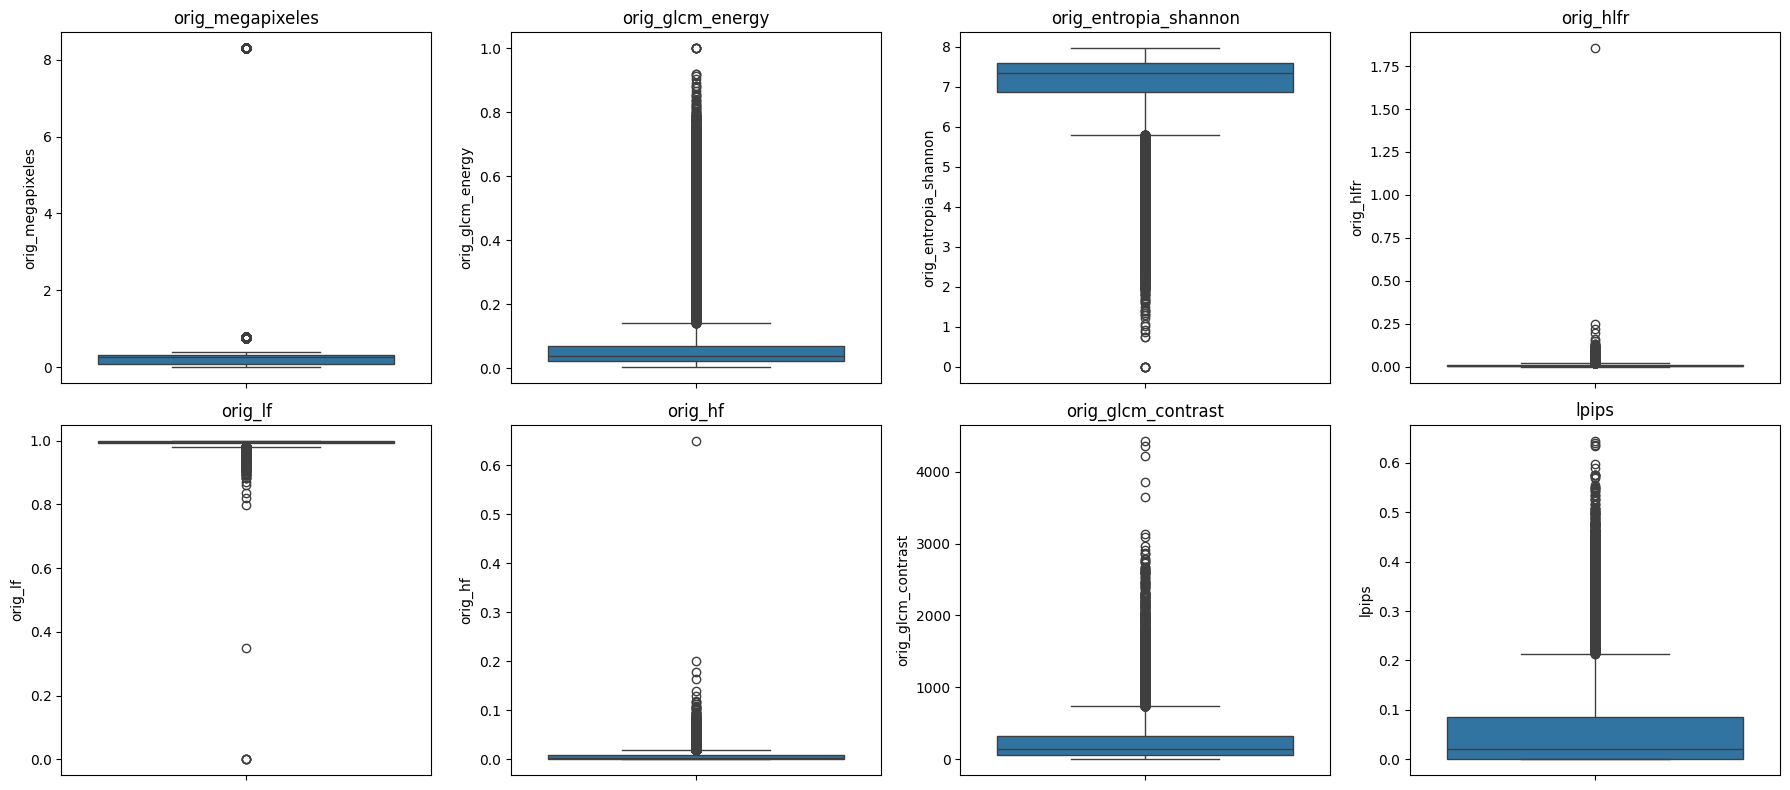


Guardado: csv/eda_outputs/boxplots_top_outliers.png


In [11]:
print("=" * 70)
print("10. DETECCION DE OUTLIERS (metodo IQR)")
print("=" * 70)
outlier_summary = []
for col in features_img + [target]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    outlier_summary.append({"feature": col, "n_outliers": n_out,
                             "pct": round(n_out / len(df) * 100, 3)})
 
outlier_df = pd.DataFrame(outlier_summary).sort_values("pct", ascending=False)
print(outlier_df.to_string(index=False))
outlier_df.to_csv(f"{OUT_DIR}/resumen_outliers_iqr.csv", index=False)
 
top_outlier_feats = outlier_df.head(8)["feature"].tolist()
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), top_outlier_feats):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/boxplots_top_outliers.png", dpi=150)
plt.show()
print(f"\nGuardado: {OUT_DIR}/boxplots_top_outliers.png")

# CELDA 11 — DISPERSION: FEATURES MAS CORRELACIONADAS CON EL TARGET

11. RELACION DE LAS FEATURES MAS CORRELACIONADAS CON LPIPS


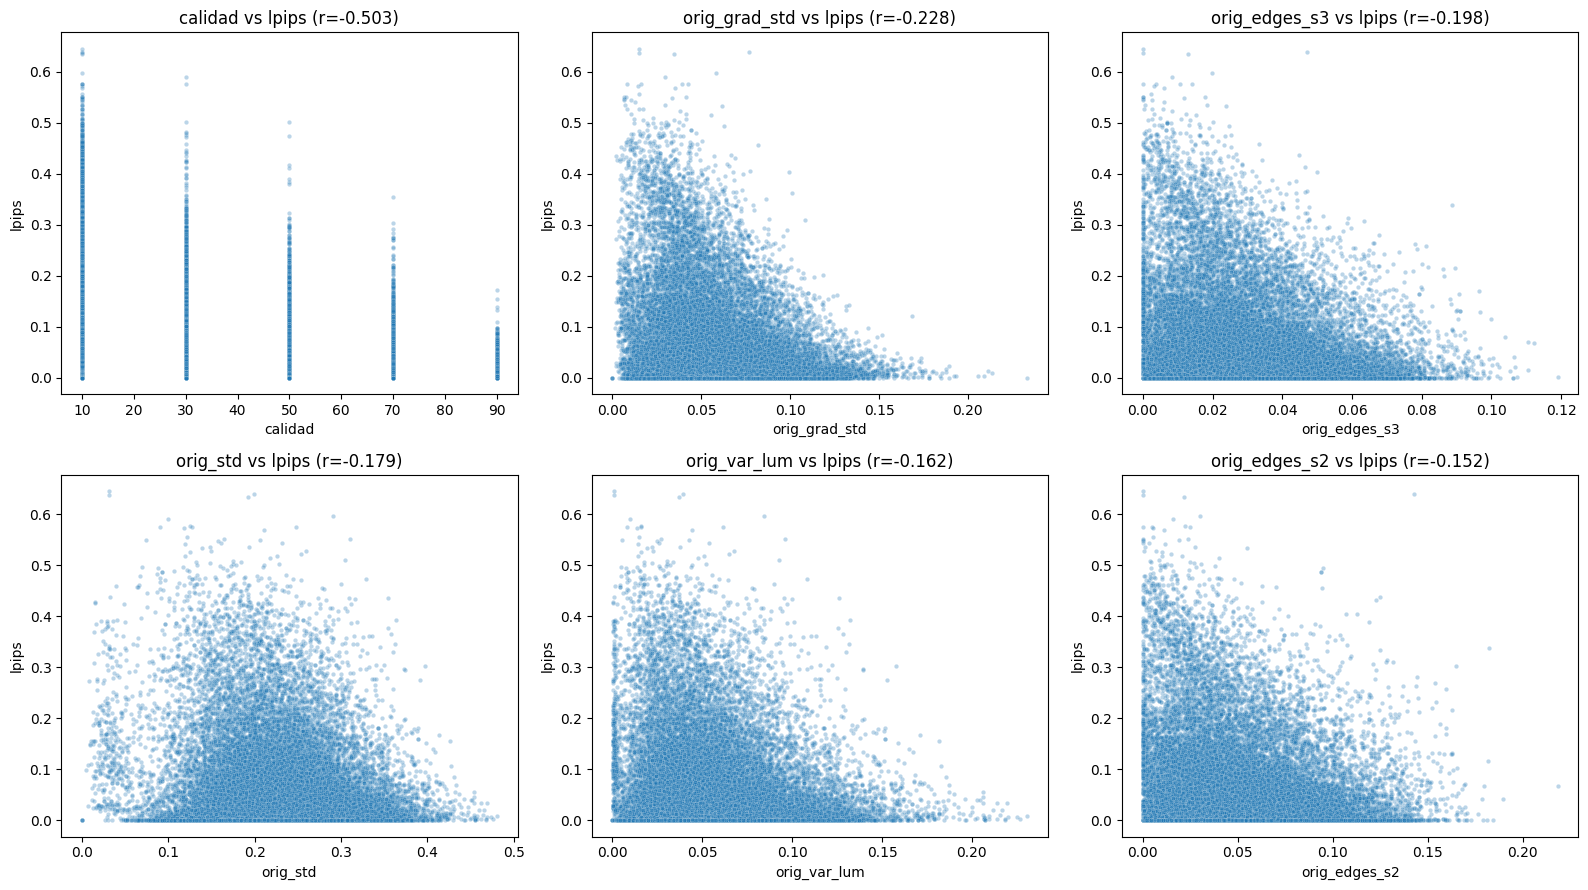

Guardado: csv/eda_outputs/scatter_top_features_vs_target.png


In [14]:
print("=" * 70)
print("11. RELACION DE LAS FEATURES MAS CORRELACIONADAS CON LPIPS")
print("=" * 70)
top_feats = corr_target.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), top_feats):
    muestra_scatter = df.sample(min(30000, len(df)), random_state=42)
    sns.scatterplot(data=muestra_scatter, x=col, y=target, alpha=0.3, s=10, ax=ax)
    ax.set_title(f"{col} vs {target} (r={corr_target[col]:.3f})")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/scatter_top_features_vs_target.png", dpi=150)
plt.show()
print(f"Guardado: {OUT_DIR}/scatter_top_features_vs_target.png")

# CELDA 12 — CORRELACION DE SPEARMAN CON LPIPS

CORRELACION DE SPEARMAN CON LPIPS (complemento a Pearson)
                feature  pearson_r  spearman_rho  diferencia_abs
                calidad  -0.503457     -0.358352       -0.145105
          orig_grad_std  -0.227866     -0.142767       -0.085098
          orig_edges_s3  -0.198184     -0.132098       -0.066086
           orig_var_lum  -0.161594     -0.115175       -0.046418
               orig_std  -0.179057     -0.115175       -0.063882
     orig_glcm_contrast  -0.122027     -0.106143       -0.015884
          orig_edges_s2  -0.152196     -0.092768       -0.059428
         orig_michelson  -0.066065     -0.091983        0.025918
         orig_grad_mean  -0.139484     -0.089561       -0.049923
             orig_rango  -0.091151     -0.087921       -0.003230
  orig_entropia_shannon   0.037284     -0.086668        0.049384
                orig_lf   0.041718      0.058981        0.017263
orig_entropia_espectral  -0.035974     -0.058790        0.022816
                orig_hf  -0.0483

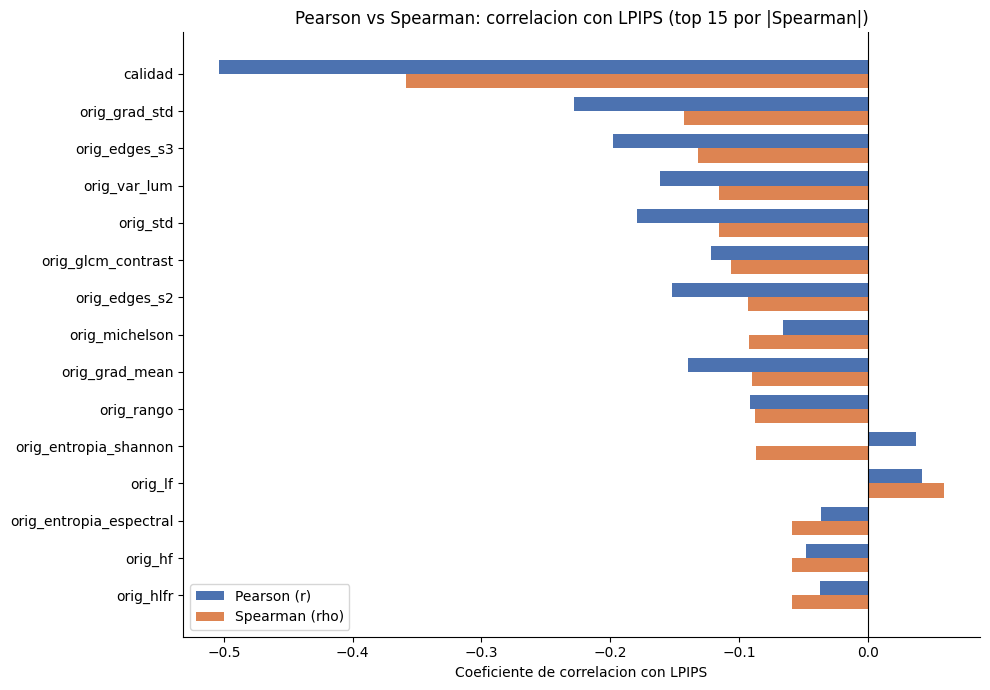


Guardado: csv/eda_outputs/comparacion_pearson_spearman.png


In [15]:
print("=" * 70)
print("CORRELACION DE SPEARMAN CON LPIPS (complemento a Pearson)")
print("=" * 70)


def correlacion_spearman_vs_target(df, target="lpips"):
    """
    Calcula la correlacion de Spearman (relacion monotona, no necesariamente
    lineal) entre cada feature numerica y la variable objetivo, y la compara
    directamente contra la correlacion de Pearson ya calculada.

    Spearman trabaja sobre los RANGOS de los datos, no sobre sus valores
    originales. Esto lo hace insensible a la forma de la distribucion
    (asimetria, colas pesadas, escala) y capaz de detectar relaciones
    monotonas no lineales que Pearson puede subestimar: por ejemplo, variables
    como orig_hf, orig_lf u orig_hlfr, con distribuciones extremadamente
    sesgadas, son candidatas naturales a mostrar una diferencia relevante
    entre ambos coeficientes.

    Retorna un DataFrame ordenado por |spearman| descendente, con columnas:
    pearson_r, spearman_rho, diferencia_abs (|spearman| - |pearson|).
    """
    cols = [c for c in df.select_dtypes(include=[np.number]).columns if c != target]

    resultados = []
    for col in cols:
        sub = df[[col, target]].dropna()
        if len(sub) < 10:
            continue
        r_pearson, _ = stats.pearsonr(sub[col], sub[target])
        rho_spearman, _ = stats.spearmanr(sub[col], sub[target])
        resultados.append({
            "feature": col,
            "pearson_r": r_pearson,
            "spearman_rho": rho_spearman,
            "diferencia_abs": abs(rho_spearman) - abs(r_pearson),
        })

    tabla = pd.DataFrame(resultados)
    tabla = tabla.sort_values("spearman_rho", key=abs, ascending=False)
    return tabla.reset_index(drop=True)


# --- Calculo ---
tabla_spearman = correlacion_spearman_vs_target(df, target=target)
print(tabla_spearman.to_string(index=False))
tabla_spearman.to_csv(f"{OUT_DIR}/correlacion_spearman_vs_target.csv", index=False)
print(f"\nGuardado: {OUT_DIR}/correlacion_spearman_vs_target.csv")

# --- Casos donde Spearman revela mas relacion que Pearson ---
print("\n" + "=" * 70)
print("Variables donde Spearman supera notablemente a Pearson (diferencia > 0.05)")
print("=" * 70)
diferencias_relevantes = tabla_spearman[tabla_spearman["diferencia_abs"] > 0.05]
if len(diferencias_relevantes):
    print(diferencias_relevantes.to_string(index=False))
else:
    print("No se encontraron diferencias relevantes (> 0.05) entre Pearson y Spearman.")

# --- Grafico comparativo ---
top = tabla_spearman.head(15).copy()
x = np.arange(len(top))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(x - width / 2, top["pearson_r"], height=width, label="Pearson (r)",
        color="#4C72B0")
ax.barh(x + width / 2, top["spearman_rho"], height=width, label="Spearman (rho)",
        color="#DD8452")
ax.set_yticks(x)
ax.set_yticklabels(top["feature"])
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coeficiente de correlacion con LPIPS")
ax.set_title("Pearson vs Spearman: correlacion con LPIPS (top 15 por |Spearman|)")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()

ruta_grafico = f"{OUT_DIR}/comparacion_pearson_spearman.png"
plt.savefig(ruta_grafico, dpi=150)
plt.show()
print(f"\nGuardado: {ruta_grafico}")

In [18]:
# Verificación independiente de Spearman para orig_hf y orig_hlfr

for feature in ["orig_hf", "orig_hlfr"]:
    sub = df[[feature, "lpips"]].dropna()

    rho, p = stats.spearmanr(
        sub[feature],
        sub["lpips"]
    )

    print("=" * 70)
    print(f"FEATURE: {feature}")
    print("=" * 70)
    print(f"Observaciones: {len(sub):,}")
    print(f"Spearman (rho): {rho:.15f}")
    print(f"Valor p:        {p:.15e}")

FEATURE: orig_hf
Observaciones: 29,989
Spearman (rho): -0.058668202468334
Valor p:        2.752177600509860e-24
FEATURE: orig_hlfr
Observaciones: 29,989
Spearman (rho): -0.058668202468334
Valor p:        2.752177600509860e-24


# CELDA 13 — RESUMEN FINAL DEL EDA

In [16]:
print("=" * 70)
print("RESUMEN FINAL DEL EDA")
print("=" * 70)
print(f"Filas: {len(df)} | Columnas: {df.shape[1]}")
print(f"Nulos totales: {df.isna().sum().sum()}")
print(f"Features con multicolinealidad alta (|r|>0.9): {len(alta_corr)} pares")
print(f"Feature mas correlacionada con {target}: "
      f"{corr_target.index[0]} (r={corr_target.iloc[0]:.4f})")
print(f"\nTodas las figuras y tablas se guardaron en la carpeta: {OUT_DIR}/")

RESUMEN FINAL DEL EDA
Filas: 29991 | Columnas: 33
Nulos totales: 402
Features con multicolinealidad alta (|r|>0.9): 5 pares
Feature mas correlacionada con lpips: calidad (r=-0.5035)

Todas las figuras y tablas se guardaron en la carpeta: csv/eda_outputs/


# Pruebas adicionales

In [6]:

df = pd.read_csv("csv/dataset_final_orig.csv")

EPS = 1e-6

cols = [
    "img_original",
    "orig_hf",
    "orig_lf",
    "orig_hlfr"
]

d = df[cols].dropna(
    subset=["orig_hf", "orig_lf", "orig_hlfr"]
).copy()

print(f"Registros analizados: {len(d):,}")

Registros analizados: 29,991


110

In [7]:
d["suma_hf_lf"] = d["orig_hf"] + d["orig_lf"]

error_suma = (d["suma_hf_lf"] - 1).abs()

ok = np.isclose(
    d["suma_hf_lf"],
    1,
    atol=1e-10
)

print(
    f"Cumplen hf + lf ≈ 1: "
    f"{ok.sum():,} ({ok.mean()*100:.4f} %)"
)

print(
    f"No cumplen: "
    f"{(~ok).sum():,} ({(~ok).mean()*100:.4f} %)"
)

print(f"Error máximo global |hf + lf - 1|: {error_suma.max():.3e}")
print(f"Error mediano |hf + lf - 1|: {error_suma.median():.3e}")
print(f"Percentil 99 del error: {error_suma.quantile(0.99):.3e}")

print("\nRegistros que no cumplen:")
print(
    d.loc[
        ~ok,
        ["img_original", "orig_hf", "orig_lf", "orig_hlfr", "suma_hf_lf"]
    ]
)

Cumplen hf + lf ≈ 1: 29,987 (99.9867 %)
No cumplen: 4 (0.0133 %)
Error máximo global |hf + lf - 1|: 1.000e+00
Error mediano |hf + lf - 1|: 2.220e-16
Percentil 99 del error: 1.221e-15

Registros que no cumplen:
                   img_original  orig_hf  orig_lf  orig_hlfr  suma_hf_lf
21760  imagenes\png\243 (2).png      0.0      0.0        0.0         0.0
21897  imagenes\png\304 (2).png      0.0      0.0        0.0         0.0
22940  imagenes\png\664 (2).png      0.0      0.0        0.0         0.0
22942      imagenes\png\664.png      0.0      0.0        0.0         0.0


112

In [9]:
def correlacion_par(x, y, nombre):
    r, _ = stats.pearsonr(x, y)
    rho, _ = stats.spearmanr(x, y)

    print(
        f"{nombre:<35} "
        f"n={len(x):>6,} | "
        f"Pearson={r:.6f} | "
        f"Spearman={rho:.6f}"
    )


# 1. Todos los registros
correlacion_par(
    d["orig_hf"],
    d["orig_lf"],
    "Conjunto completo"
)


# 2. Sin los cuatro casos hf=0 y lf=0
sin_00 = ~(
    (d["orig_hf"] == 0) &
    (d["orig_lf"] == 0)
)

correlacion_par(
    d.loc[sin_00, "orig_hf"],
    d.loc[sin_00, "orig_lf"],
    "Sin casos hf=lf=0"
)


# 3. Solo registros que cumplen hf+lf≈1
correlacion_par(
    d.loc[ok, "orig_hf"],
    d.loc[ok, "orig_lf"],
    "Solo hf+lf≈1"
)

Conjunto completo                   n=29,991 | Pearson=-0.669815 | Spearman=-0.999200
Sin casos hf=lf=0                   n=29,987 | Pearson=-1.000000 | Spearman=-1.000000
Solo hf+lf≈1                        n=29,987 | Pearson=-1.000000 | Spearman=-1.000000


114

In [20]:
dd = d.loc[ok].copy()

dd["hlfr_calculado"] = (
    dd["orig_hf"] / dd["orig_lf"]
)

error_abs = (
    dd["orig_hlfr"] - dd["hlfr_calculado"]
).abs()

print(f"Error absoluto máximo: {error_abs.max():.12e}")
print(f"Error absoluto medio: {error_abs.mean():.12e}")
print(
    f"Registros con diferencia > 1e-12: "
    f"{(error_abs > 1e-12).sum()}"
)

Error absoluto máximo: 3.133929116217e-09
Error absoluto medio: 1.045465320012e-13
Registros con diferencia > 1e-12: 1


116

In [11]:
# Correlación en el conjunto completo
correlacion_par(
    d["orig_hf"],
    d["orig_hlfr"],
    "hf vs hlfr - completo"
)


# Correlación únicamente en los registros hf+lf≈1
correlacion_par(
    dd["orig_hf"],
    dd["orig_hlfr"],
    "hf vs hlfr - complementarios"
)

hf vs hlfr - completo               n=29,991 | Pearson=0.905517 | Spearman=1.000000
hf vs hlfr - complementarios        n=29,987 | Pearson=0.905515 | Spearman=1.000000


118

In [12]:
# Ordenar por HF
s = dd.sort_values("orig_hf").copy()

# Diferencias sucesivas de HLFR
diferencias = s["orig_hlfr"].diff().dropna()

# Tolerancia numérica
violaciones = (
    diferencias < -1e-9
).sum()

print(
    f"Violaciones de monotonía: {violaciones}"
)

print(
    f"Total de comparaciones: {len(diferencias):,}"
)

Violaciones de monotonía: 0
Total de comparaciones: 29,986


120

In [13]:
ceros = df[
    (df["orig_hf"] == 0) &
    (df["orig_lf"] == 0)
]

nan_espectral = df[
    df["orig_entropia_espectral"].isna()
]

interseccion = set(ceros.index) & set(nan_espectral.index)

print(f"Casos hf=lf=0: {len(ceros)}")
print(f"NaN en entropia_espectral: {len(nan_espectral)}")
print(f"Intersección: {len(interseccion)}")

print("\nCasos hf=lf=0:")
print(
    ceros[
        [
            "img_original",
            "orig_hf",
            "orig_lf",
            "orig_hlfr",
            "orig_entropia_espectral"
        ]
    ]
)

Casos hf=lf=0: 4
NaN en entropia_espectral: 4
Intersección: 4

Casos hf=lf=0:
                   img_original  orig_hf  orig_lf  orig_hlfr  \
21760  imagenes\png\243 (2).png      0.0      0.0        0.0   
21897  imagenes\png\304 (2).png      0.0      0.0        0.0   
22940  imagenes\png\664 (2).png      0.0      0.0        0.0   
22942      imagenes\png\664.png      0.0      0.0        0.0   

       orig_entropia_espectral  
21760                      NaN  
21897                      NaN  
22940                      NaN  
22942                      NaN  


122

In [23]:
r_total, _ = stats.pearsonr(
    d["orig_hf"],
    d["orig_lf"]
)

r_sin_00, _ = stats.pearsonr(
    d.loc[sin_00, "orig_hf"],
    d.loc[sin_00, "orig_lf"]
)

rho_hf_hlfr, _ = stats.spearmanr(
    dd["orig_hf"],
    dd["orig_hlfr"]
)

# Comparación directa entre orig_hlfr y orig_hf / orig_lf
hlfr_calculado = (
    dd["orig_hf"] / dd["orig_lf"]
)

error_hlfr = (
    dd["orig_hlfr"] - hlfr_calculado
).abs()

diferencias_hlfr = (
    error_hlfr > 1e-12
).sum()

print("========== RESUMEN ==========")

print(f"Registros analizados: {len(d):,}")
print(f"Casos hf=lf=0: {(~sin_00).sum()}")
print(f"Casos hf+lf≈1: {ok.sum():,}")

print(f"Pearson HF-LF total: {r_total:.6f}")
print(f"Pearson HF-LF sin (0,0): {r_sin_00:.6f}")

print(f"Spearman HF-HLFR: {rho_hf_hlfr:.6f}")

print(
    f"Error máximo HLFR - (HF/LF): "
    f"{error_hlfr.max():.12e}"
)

print(
    f"Error medio HLFR - (HF/LF): "
    f"{error_hlfr.mean():.12e}"
)

print(
    f"Diferencias HLFR - (HF/LF) > 1e-12: "
    f"{diferencias_hlfr}"
)

print(f"Violaciones de monotonía: {violaciones}")

print(
    f"Intersección (0,0) / NaN espectral: "
    f"{len(interseccion)}"
)

========== RESUMEN ==========
Registros analizados: 29,991
Casos hf=lf=0: 4
Casos hf+lf≈1: 29,987
Pearson HF-LF total: -0.669815
Pearson HF-LF sin (0,0): -1.000000
Spearman HF-HLFR: 1.000000
Error máximo HLFR - (HF/LF): 3.133929116217e-09
Error medio HLFR - (HF/LF): 1.045465320012e-13
Diferencias HLFR - (HF/LF) > 1e-12: 1
Violaciones de monotonía: 0
Intersección (0,0) / NaN espectral: 4
